In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA

# Reproductibilité
np.random.seed(42)


## Chargement dataset ##

In [2]:
df = pd.read_csv('Données/X_train_clean.csv')
print(f"Dimensions : {df.shape}")
df.head()

Dimensions : (444, 34)


,Family_Size,PPI_Intersection,PPI_Union,PPI_Jaccard,Pfam_Inter,Pfam_Union,Pfam_Jaccard,Ks,Ka,Ka_Ks,...,Expression_Data_Missing,TE_Env_Pair_TE-free_TE-free,TE_Env_Pair_TE-free_TE-poor,TE_Env_Pair_TE-free_TE-rich,TE_Env_Pair_TE-poor_TE-poor,TE_Env_Pair_TE-poor_TE-rich,TE_Env_Pair_TE-rich_TE-rich,TE_Env_Class_free,TE_Env_Class_half,TE_Env_Class_rich
0,4,1.0,9.0,11.111111,1.0,1.0,1.0,1.8192,0.4049,0.222570,...,0,True,False,False,False,False,False,True,False,False
1,4,1.0,14.0,7.142857,1.0,1.0,1.0,1.9732,0.4109,0.208240,...,0,False,False,True,False,False,False,False,True,False
2,2,12.0,32.0,37.500000,1.0,1.0,1.0,2.3106,0.5092,0.220376,...,0,True,False,False,False,False,False,True,False,False
3,17,1.0,14.0,7.142857,3.0,3.0,1.0,1.6167,0.3528,0.218222,...,0,False,True,False,False,False,False,False,True,False
4,17,0.0,7.0,0.000000,3.0,3.0,1.0,8.2558,0.4092,0.049565,...,0,False,True,False,False,False,False,False,True,False


In [3]:
# Récupérer les variables numériques et les stocker dans une liste
num_cols = df.select_dtypes(include=['float64', 'int64']).columns
X_num = df[num_cols]

numeric_cols = X_num.columns.tolist()
print(f"Colonnes numériques : {numeric_cols}")

Colonnes numériques : ['Family_Size', 'PPI_Intersection', 'PPI_Union', 'PPI_Jaccard', 'Pfam_Inter', 'Pfam_Union', 'Pfam_Jaccard', 'Ks', 'Ka', 'Ka_Ks', 'Ks_SD', 'Ka_SD', 'Distance', 'TE_Coverage_Asymmetry', 'TE_Coverage_Mean', 'TE_Number_Asymmetry', 'TE_Number_Mean', 'PPI_Interactant_Asymmetry', 'PPI_Interactant_Mean', 'Pfam_Asymmetry', 'Pfam_Mean', 'TE_Density_Asymmetry', 'TE_Density_Mean', 'TE_Env_Match', 'Expression_Data_Missing']


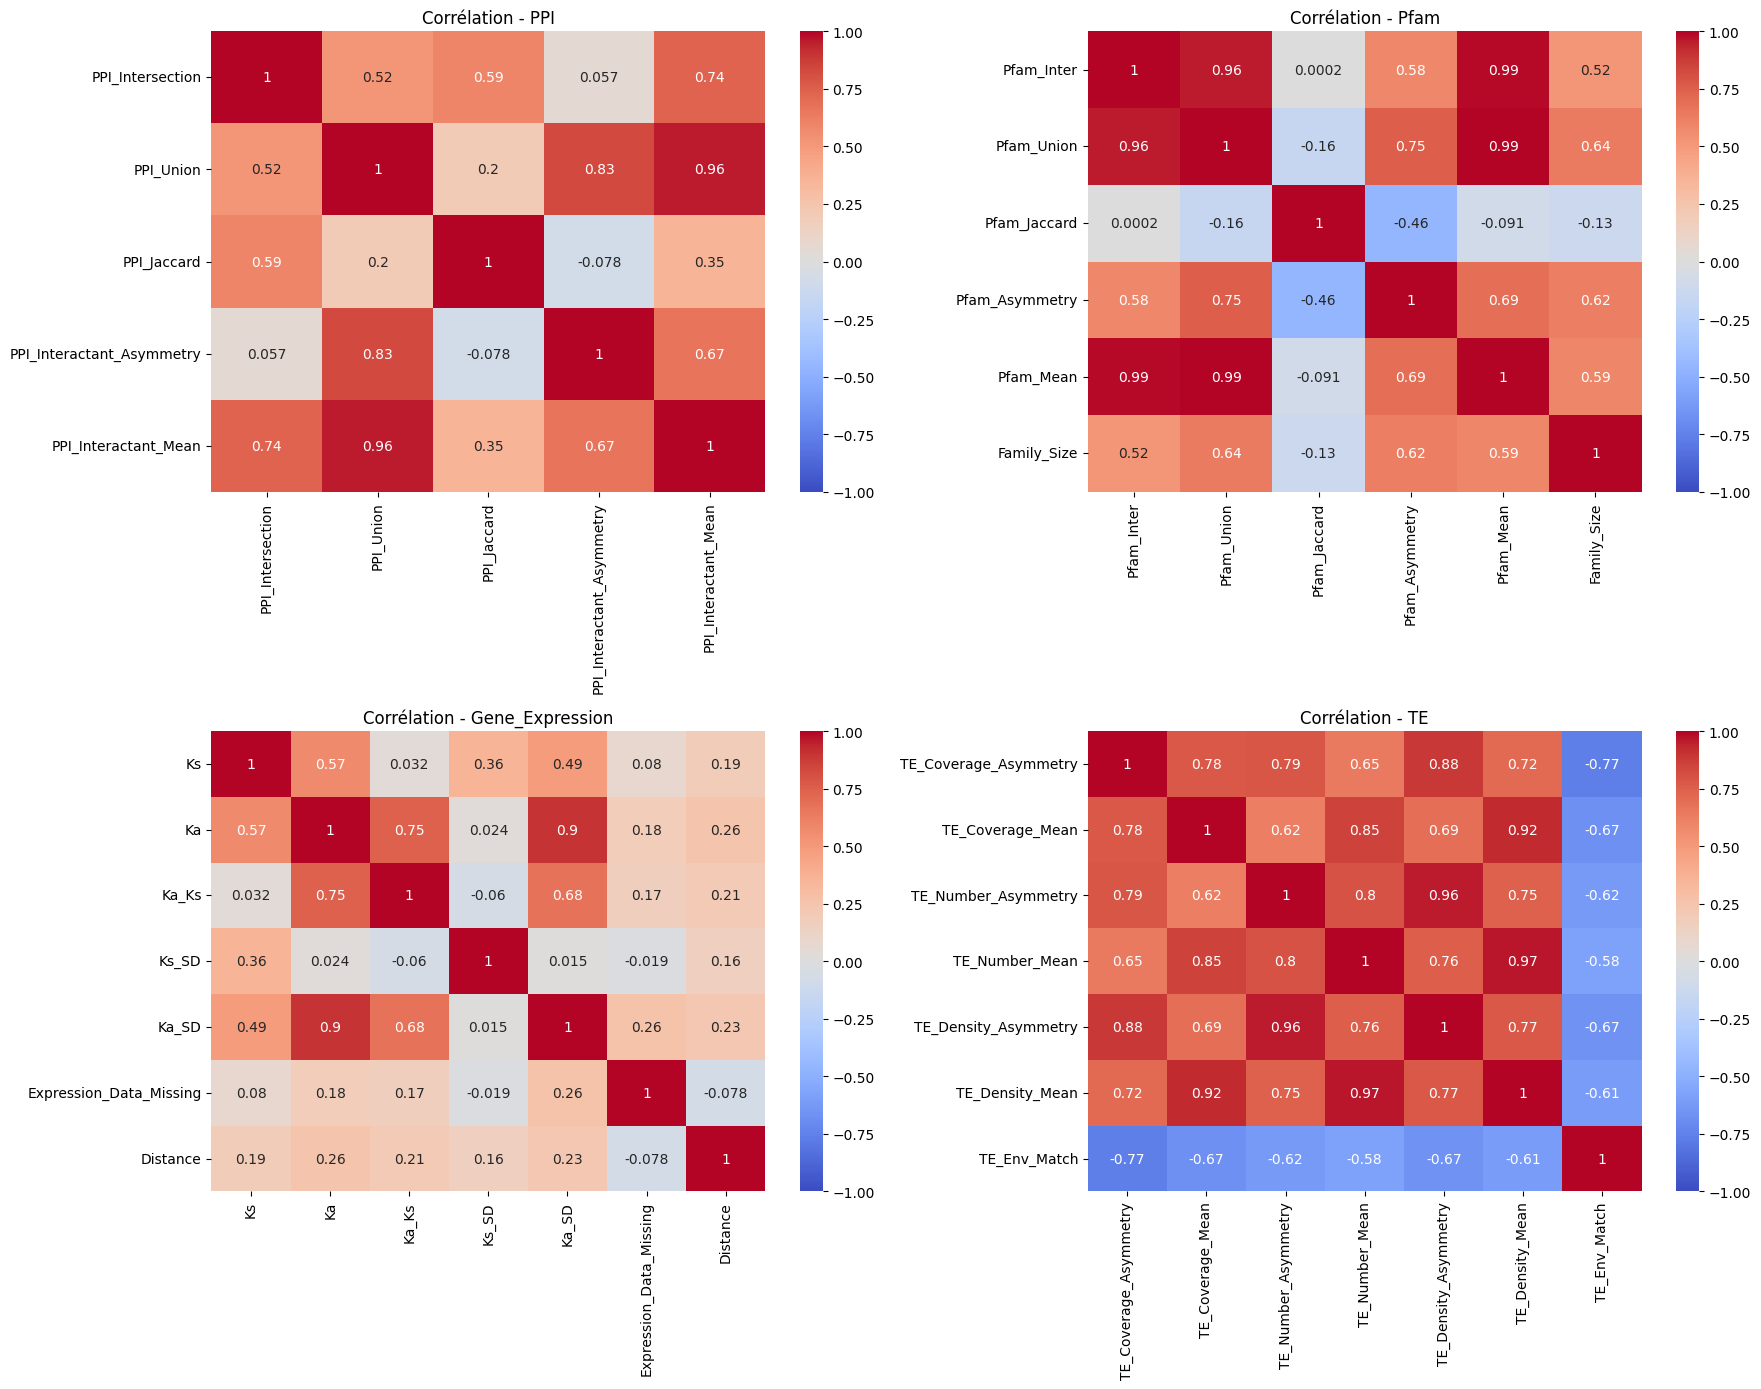

In [4]:
# Grouper les variables numériques en catégories selon leur nature
categories = {
    'PPI': ['PPI_Intersection', 'PPI_Union', 'PPI_Jaccard', 'PPI_Interactant_Asymmetry', 'PPI_Interactant_Mean'],
    'Pfam': ['Pfam_Inter', 'Pfam_Union', 'Pfam_Jaccard', 'Pfam_Asymmetry', 'Pfam_Mean', 'Family_Size'],
    'Gene_Expression': ['Ks', 'Ka', 'Ka_Ks', 'Ks_SD', 'Ka_SD', 'Expression_Data_Missing', 'Distance'],
    'TE': ['TE_Coverage_Asymmetry', 'TE_Coverage_Mean', 'TE_Number_Asymmetry', 
           'TE_Number_Mean', 'TE_Density_Asymmetry', 'TE_Density_Mean', 'TE_Env_Match'],}

# Matrice de corrélation pour les groupes et visualisation avec une heatmap
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
for i, (group, cols) in enumerate(categories.items()):
    ax = axes.flat[i]
    corr_matrix = X_num[cols].corr()
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
    ax.set_title(f'Corrélation - {group}')
fig.tight_layout()
fig.savefig('Plots/t_SNE_family/correlation_heatmaps.png', dpi=150, bbox_inches='tight')
plt.show()

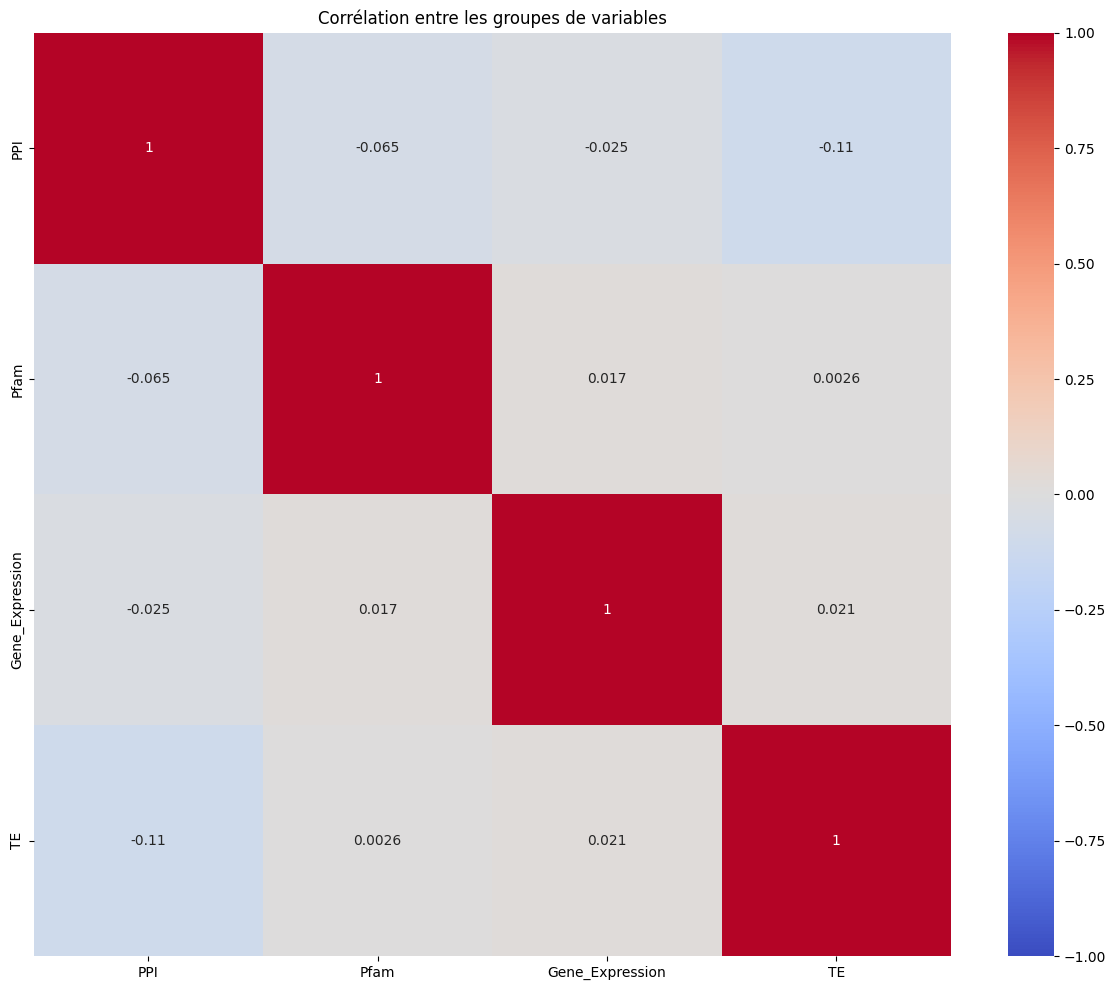

In [5]:
# Matrice de corrélation globale avec les groupes de variables qui représentent les différentes catégories
plt.figure(figsize=(12, 10))
group_means = {group: X_num[cols].mean(axis=1) for group, cols in categories.items()}
group_df = pd.DataFrame(group_means)
corr_matrix = group_df.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Corrélation entre les groupes de variables')
plt.tight_layout()
plt.savefig('Plots/t_SNE_family/correlation_groups.png', dpi=150, bbox_inches='tight')
plt.show()

## Preprocessing des variables ##

In [6]:
# Préparation des données pour t-SNE en utilisant les groupes de variables
# Définition de X à partir des groupes de variables
X = group_df.values

# Standardisation
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## t-SNE sans PCA ##

### t-SNE Classification sans PCA ###

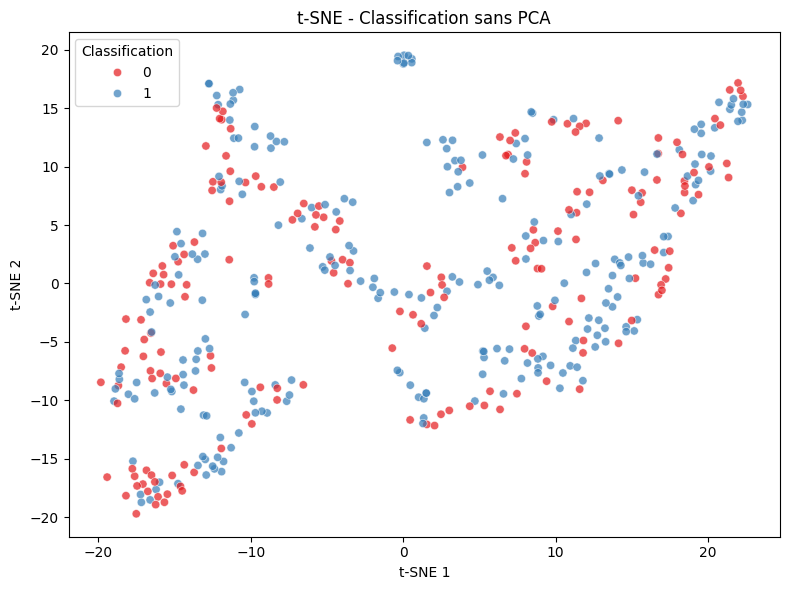

In [7]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate='auto',
    max_iter=1000,
    init='random',
    random_state=42,
)

# Récupérer Classification pour t-SNE 
y_train = pd.read_csv("Données/Y_train_clean.csv")

X_tsne_random = tsne.fit_transform(X_scaled)

df_tsne_random = pd.DataFrame(X_tsne_random, columns=['tSNE_1', 'tSNE_2'])
df_tsne_random['orig_index'] = df.index

# Visualisation t-SNE colorée par la Classification
plt.figure(figsize=(8, 6))
sns.scatterplot(x=df_tsne_random['tSNE_1'], y=df_tsne_random['tSNE_2'], hue=y_train['Classification'], palette='Set1', alpha=0.7)
plt.title('t-SNE - Classification sans PCA')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.legend(title='Classification')
plt.tight_layout()
plt.savefig('Plots/t_SNE_family/tsne_classification_sans_pca.png', dpi=300)
plt.show()

/mnt/c/Users/thoma/OneDrive/Documents/ENSIIE/Master/Stage 3A/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


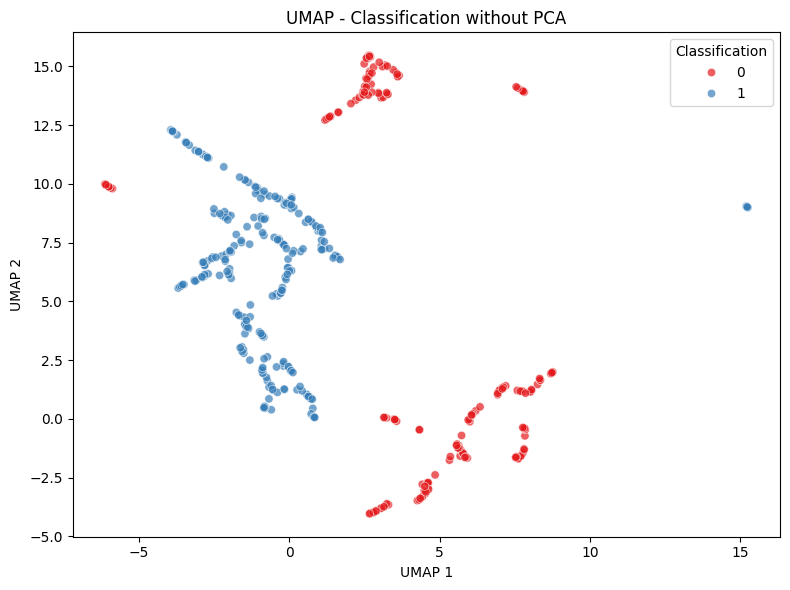

In [8]:
import umap

reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric='euclidean',
    random_state=42,
)

# Récupérer Y_train pour UMAP 
y_train = pd.read_csv("Données/Y_train_clean.csv")
    
X_umap = reducer.fit_transform(X_scaled, y = y_train.iloc[:, 0])

df_umap = pd.DataFrame(X_umap, columns=['UMAP_1', 'UMAP_2'])
df_umap['orig_index'] = df.index

# Visualisation UMAP colorée par Y
plt.figure(figsize=(8, 6))
sns.scatterplot(x=df_umap['UMAP_1'], y=df_umap['UMAP_2'], hue=y_train.iloc[:, 0], palette='Set1', alpha=0.7)
plt.title('UMAP - Classification without PCA')
plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2')
plt.legend(title='Classification')
plt.tight_layout()
plt.savefig('Plots/t_SNE_family/umap_classification_sans_pca.png', dpi=300)
plt.show()

/mnt/c/Users/thoma/OneDrive/Documents/ENSIIE/Master/Stage 3A/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


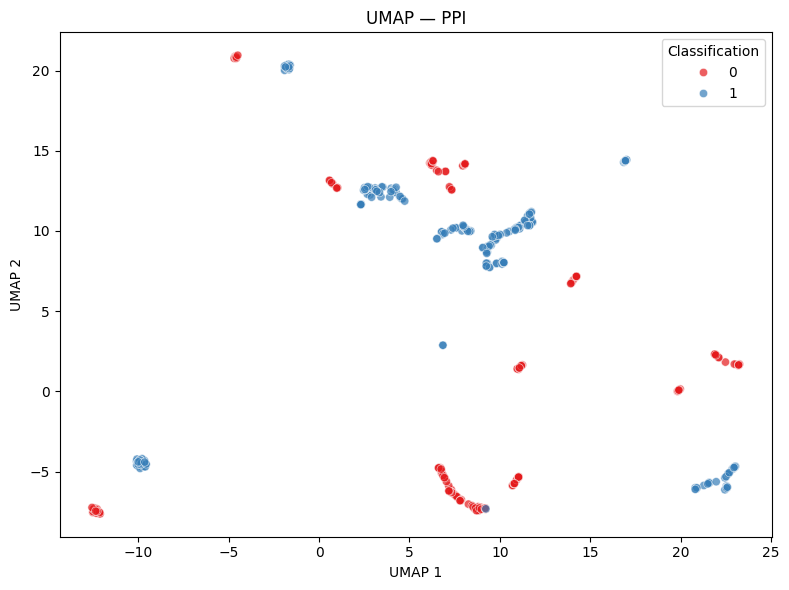

/mnt/c/Users/thoma/OneDrive/Documents/ENSIIE/Master/Stage 3A/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


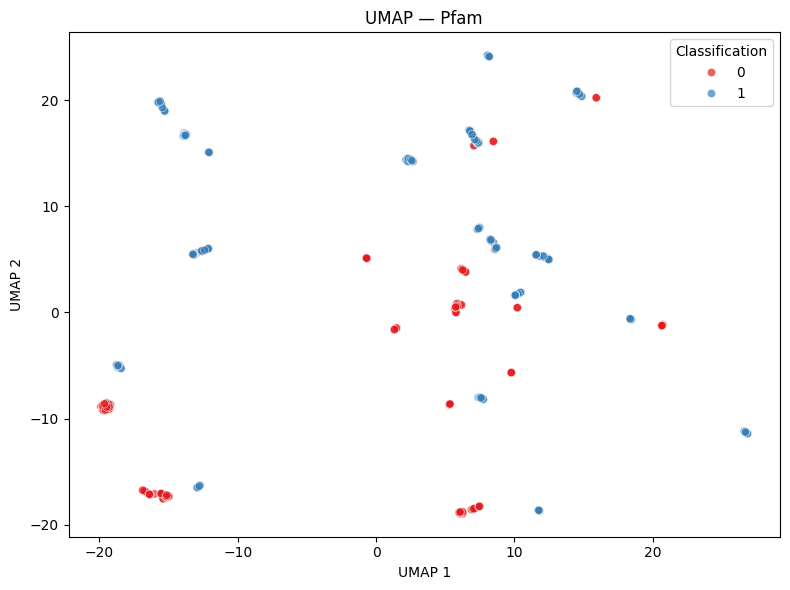

/mnt/c/Users/thoma/OneDrive/Documents/ENSIIE/Master/Stage 3A/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


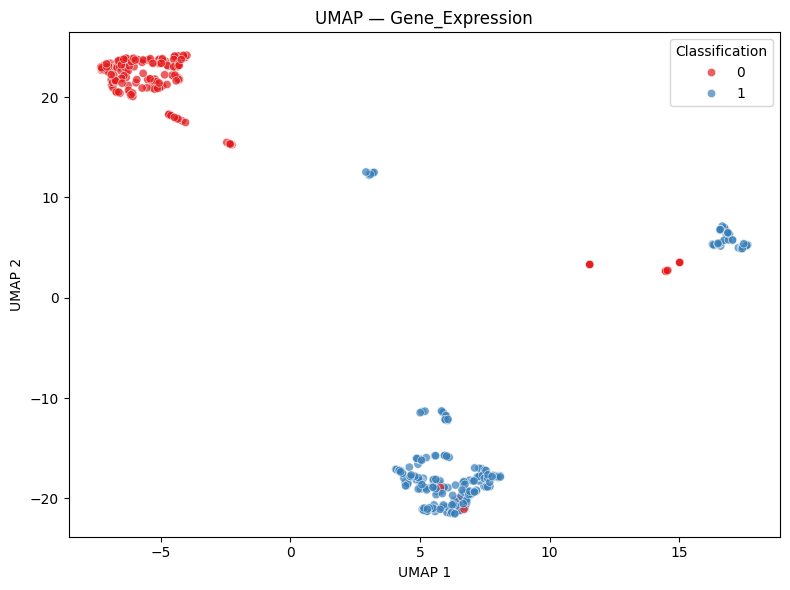

/mnt/c/Users/thoma/OneDrive/Documents/ENSIIE/Master/Stage 3A/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


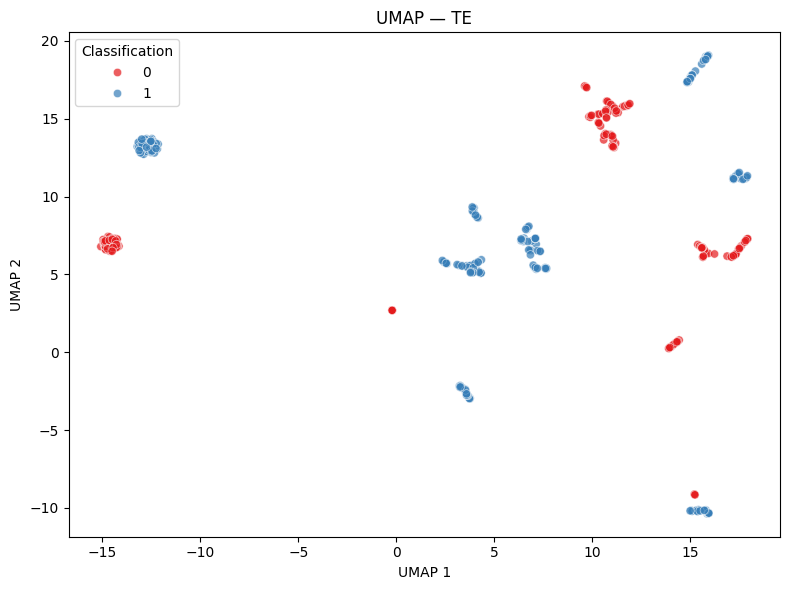

In [9]:
import os

# UMAP par famille de descripteurs

y_train = pd.read_csv("Données/Y_train_clean.csv").reindex(df.index).reset_index(drop=True)

group_col = 'Classification'
if group_col not in y_train.columns:
    raise KeyError(f"Colonne '{group_col}' absente dans Données/Y_train_clean.csv")

for group, cols in categories.items():
    cols_present = [c for c in cols if c in X_num.columns]
    if len(cols_present) < 2:
        print(f"Le groupe '{group}' a trop peu de variables pour UMAP, skip.")
        continue

    X_group = X_num[cols_present].values
    X_group_scaled = StandardScaler().fit_transform(X_group)

    reducer = umap.UMAP(
        n_components=2,
        n_neighbors=15,
        min_dist=0.1,
        metric='euclidean',
        random_state=42,
    )
    X_umap_group = reducer.fit_transform(X_group_scaled, y=y_train[group_col])

    df_umap_group = pd.DataFrame(X_umap_group, columns=['UMAP_1', 'UMAP_2'])
    df_umap_group[group_col] = y_train[group_col]

    plt.figure(figsize=(8, 6))
    sns.scatterplot(
        data=df_umap_group,
        x='UMAP_1',
        y='UMAP_2',
        hue=group_col,
        palette='Set1',
        alpha=0.7
    )
    plt.title(f'UMAP — {group}')
    plt.xlabel('UMAP 1')
    plt.ylabel('UMAP 2')
    plt.legend(title=group_col)
    plt.tight_layout()

    out_dir = 'Plots/t_SNE_family/umap_familles'
    os.makedirs(out_dir, exist_ok=True)
    plt.savefig(os.path.join(out_dir, f'umap_{group.lower()}.png'), dpi=300, bbox_inches='tight')
    plt.show()


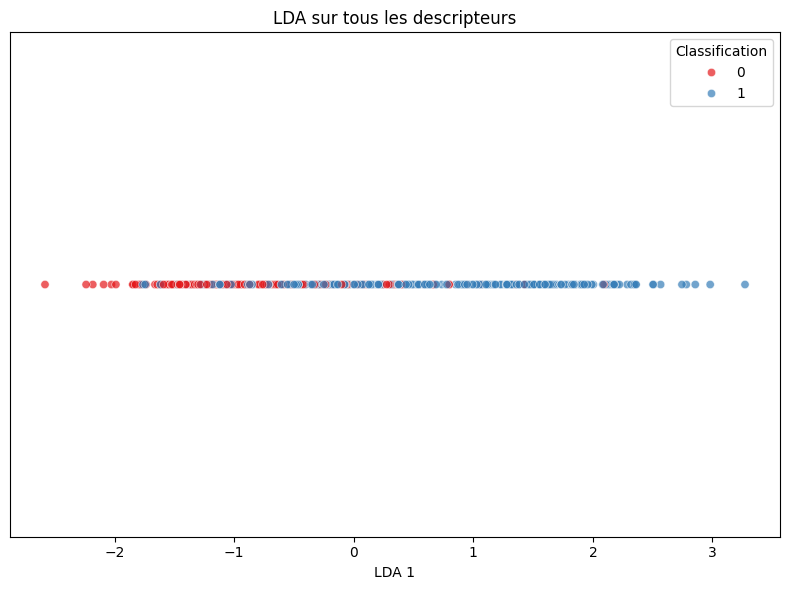

Shape après LDA : (444, 1)


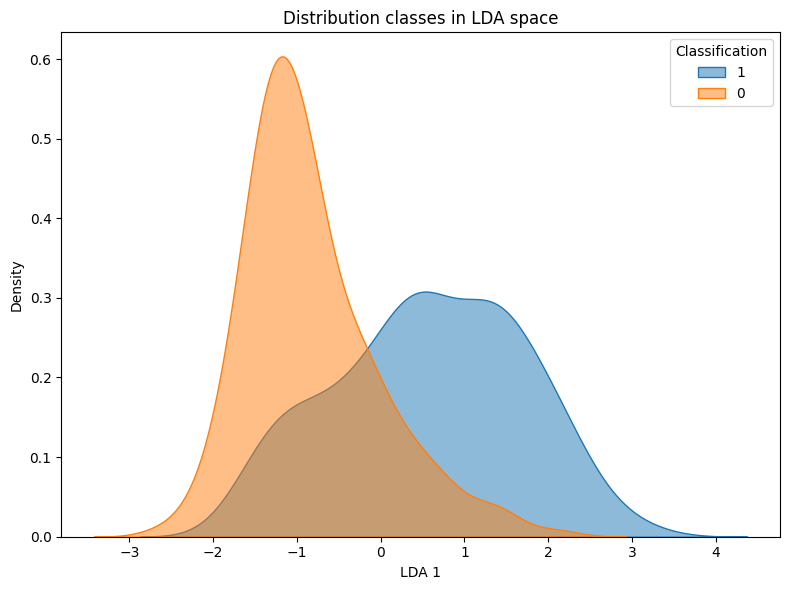

In [10]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# LDA sur tous les descripteurs numériques

y_train = pd.read_csv("Données/Y_train_clean.csv").reindex(df.index).reset_index(drop=True)

X_all = X_num.copy()
scaler = StandardScaler()
X_all_scaled = scaler.fit_transform(X_all)

n_components = min(2, len(y_train['Classification'].dropna().unique()) - 1)
lda = LinearDiscriminantAnalysis(n_components=n_components)
X_lda = lda.fit_transform(X_all_scaled, y_train['Classification'])

if n_components == 1:
    df_lda = pd.DataFrame({'LDA_1': X_lda[:, 0], 'Classification': y_train['Classification']})
else:
    df_lda = pd.DataFrame(X_lda, columns=['LDA_1', 'LDA_2'])
    df_lda['Classification'] = y_train['Classification']

plt.figure(figsize=(8, 6))
if n_components == 1:
    sns.scatterplot(data=df_lda, x='LDA_1', y=np.zeros(len(df_lda)), hue='Classification', palette='Set1', alpha=0.7)
    plt.ylabel('')
    plt.yticks([])
else:
    sns.scatterplot(data=df_lda, x='LDA_1', y='LDA_2', hue='Classification', palette='Set1', alpha=0.7)
plt.title('LDA sur tous les descripteurs')
plt.xlabel('LDA 1')
plt.tight_layout()
plt.savefig('Plots/t_SNE_family/lda_all_descriptors.png', dpi=300, bbox_inches='tight')
plt.show()

print("Shape après LDA :", X_lda.shape)

# fais un kde plot pour visualiser la distribution des classes dans l'espace LDA
plt.figure(figsize=(8, 6))
if n_components == 1:
    for cls in df_lda['Classification'].unique():
        sns.kdeplot(df_lda[df_lda['Classification'] == cls]['LDA_1'], label=cls, fill=True, alpha=0.5)
    plt.xlabel('LDA 1')
else:
    for cls in df_lda['Classification'].unique():
        sns.kdeplot(
            x=df_lda[df_lda['Classification'] == cls]['LDA_1'],
            y=df_lda[df_lda['Classification'] == cls]['LDA_2'],
            label=cls,
            fill=True,
            alpha=0.5
        )
    plt.xlabel('LDA 1')
    plt.ylabel('LDA 2')
plt.title('Distribution classes in LDA space')
plt.legend(title='Classification')
plt.tight_layout()
# plt.savefig('Plots/t_SNE_family/lda_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

In [11]:
# Affiche un tableau avec les coefficients ordonnées par valeur absolue de LDA pour chaque descripteur
coef_df = pd.DataFrame(lda.coef_, columns=X_all.columns)
coef_df = coef_df.T
coef_df['max_abs_coef'] = coef_df.abs().max(axis=1)
coef_df_sorted = coef_df.sort_values(by='max_abs_coef', ascending=False)
coef_df_sorted.head(10)  # Affiche les 10 descripteurs les plus importants selon LDA

,0,max_abs_coef
Ka,1.993133,1.993133
TE_Coverage_Mean,-0.912726,0.912726
Ka_SD,-0.868410,0.868410
TE_Density_Asymmetry,-0.865482,0.865482
TE_Density_Mean,0.810891,0.810891
Expression_Data_Missing,0.443400,0.443400
PPI_Union,0.424895,0.424895
TE_Number_Asymmetry,0.388823,0.388823
PPI_Interactant_Mean,0.360598,0.360598
TE_Coverage_Asymmetry,0.339420,0.339420


### Analyse perplexité t-SNE Classification sans PCA ###

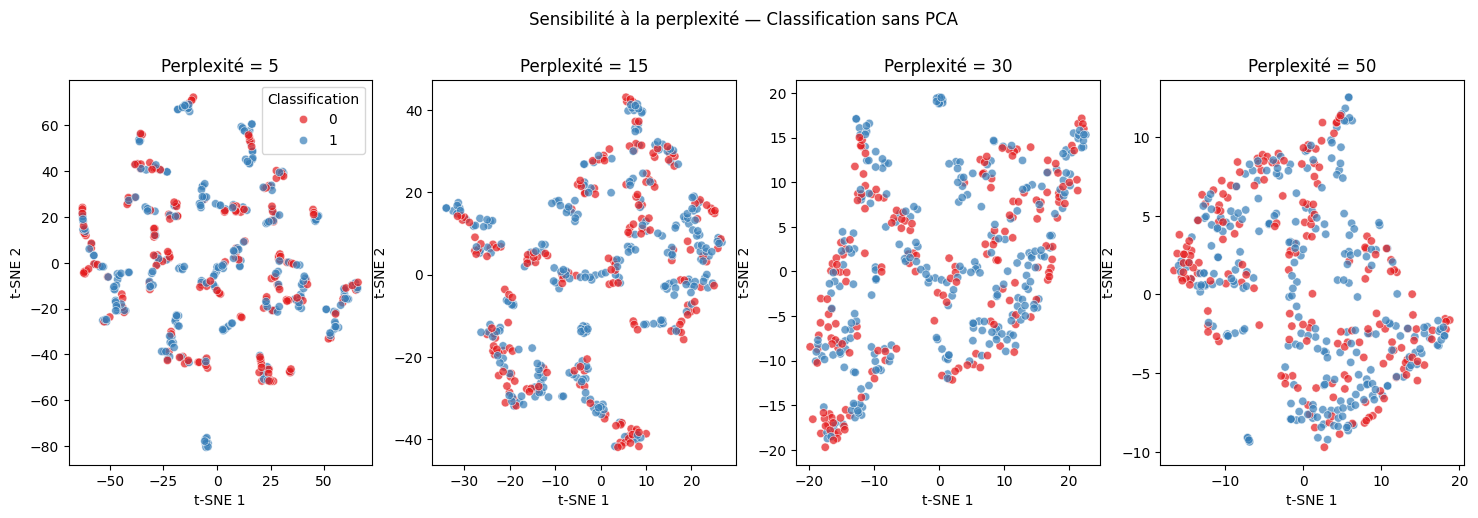

In [12]:
# Analyse de la sensibilité de t-SNE à la perplexité
perplexities = [5, 15, 30, 50]
fig, axes = plt.subplots(1, len(perplexities), figsize=(18, 5))
group_col = 'Classification' if 'Classification' in y_train.columns else print("Colonne 'Classification' non trouvée.")
for i, perp in enumerate(perplexities):
    tsne = TSNE(
        n_components=2,
        perplexity=perp,
        learning_rate='auto',
        max_iter=1000,
        init='random',
        random_state=42,
    )
    X_tsne_perp_random = tsne.fit_transform(X_scaled)
    df_tsne_perp_random = pd.DataFrame(X_tsne_perp_random, columns=['tSNE_1', 'tSNE_2'])
    df_tsne_perp_random['orig_index'] = df.index
    
    sns.scatterplot(x=df_tsne_perp_random['tSNE_1'], y=df_tsne_perp_random['tSNE_2'], hue=y_train['Classification'], palette='Set1', alpha=0.7, ax=axes[i])
    axes[i].set_title(f'Perplexité = {perp}')
    axes[i].set_xlabel('t-SNE 1')
    axes[i].set_ylabel('t-SNE 2')
    if i == 0:
        axes[i].legend(title='Classification')
    else:
        axes[i].get_legend().remove()
plt.suptitle(f"Sensibilité à la perplexité — {group_col} sans PCA", y=1.02)
# Supprimer les axes vides s'il y en a
for j in range(i+1, len(axes)):
    axes[j].set_visible(False)


### Overlay famille de descripteurs sans PCA ###

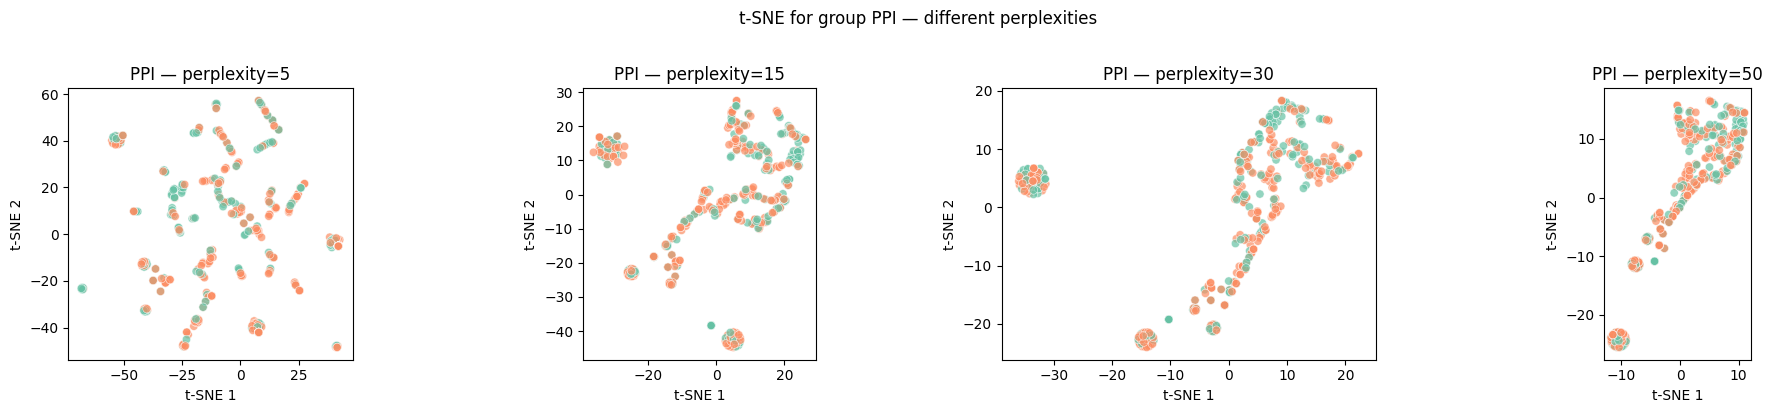

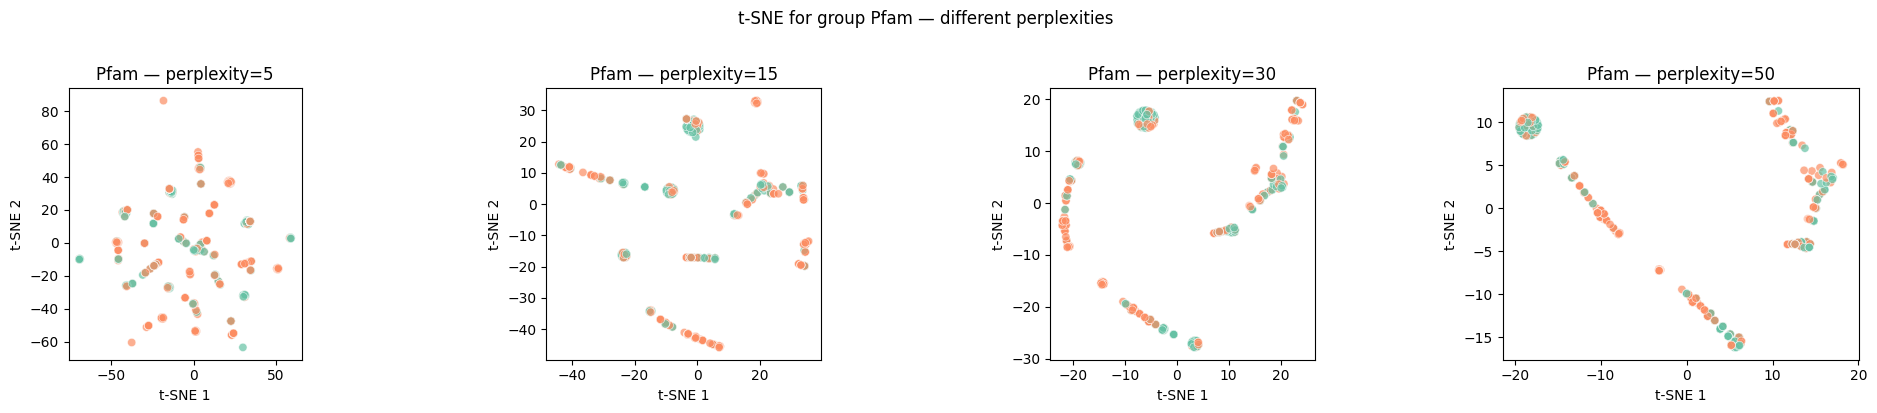

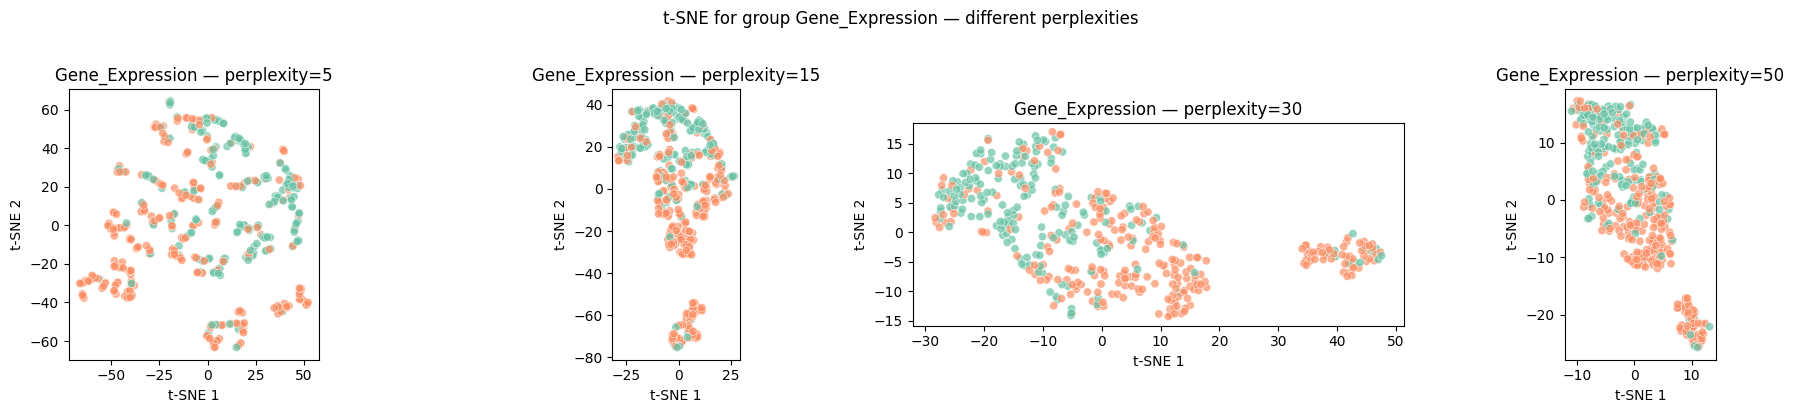

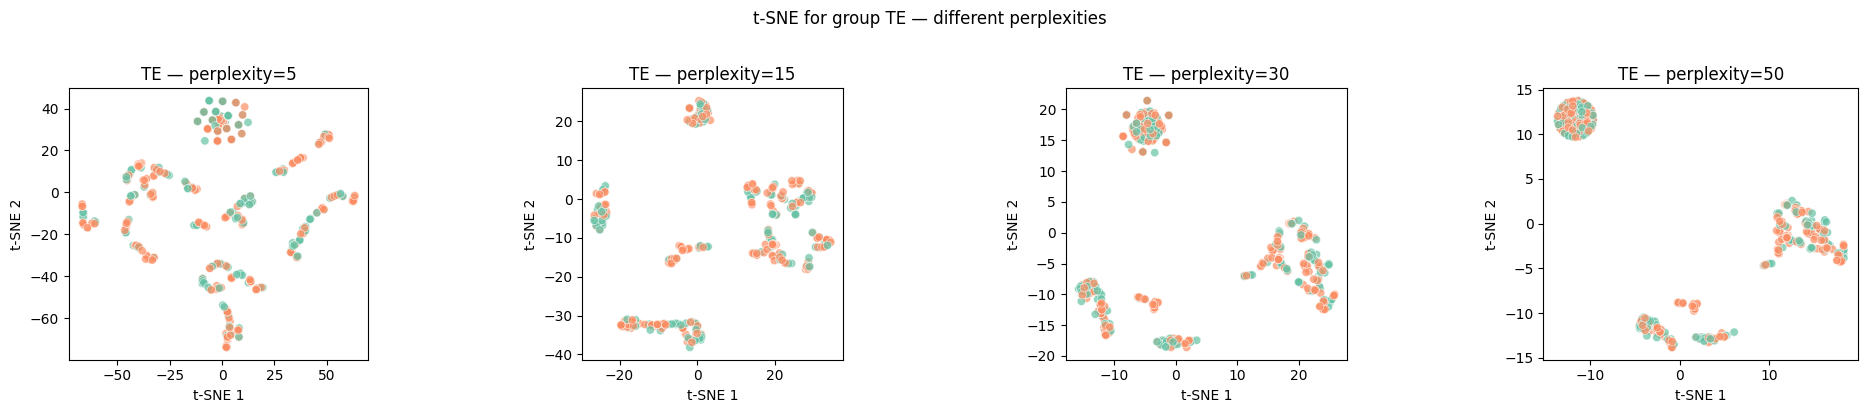

In [13]:
# Pour chaque groupe, créer une figure avec les 4 perplexités en sous-plot
import os
perplexities = [5, 15, 30, 50]

# Récupérer les labels de Classification et s'assurer de l'alignement des index
y_train = pd.read_csv("Données/Y_train_clean.csv")
y_train = y_train.reindex(df.index).reset_index(drop=True)

# Si la colonne n'existe pas, on arrête proprement
group_col = 'Classification'
if group_col not in y_train.columns:
    raise KeyError(f"Colonne '{group_col}' absente dans Données/Y_train_clean.csv")

group_labels = sorted(y_train[group_col].dropna().unique())
palette = sns.color_palette('Set2', n_colors=len(group_labels))

# Boucle sur les groupes
for group, cols in categories.items():
    if len(cols) <= 2:
        print(f"Le groupe '{group}' a moins de 2 descripteurs, t-SNE non applicable. Skipping.")
        continue

    X_group = X_num[cols].values
    X_group_scaled = StandardScaler().fit_transform(X_group)

    fig, axes = plt.subplots(1, len(perplexities), figsize=(5*len(perplexities), 4))
    # s'assurer que axes est itérable (au cas où len(perplexities)==1)
    axes = np.atleast_1d(axes)

    for ax, perp in zip(axes, perplexities):
        tsne = TSNE(n_components=2, 
                    perplexity=perp, 
                    learning_rate='auto', 
                    max_iter=1000, init='random', 
                    random_state=42)
        emb = tsne.fit_transform(X_group_scaled)

        df_tsne_group = pd.DataFrame(emb, columns=['tSNE_1', 'tSNE_2'])
        df_tsne_group['Classification'] = y_train[group_col]

        sns.scatterplot(x='tSNE_1', y='tSNE_2', hue='Classification', data=df_tsne_group, palette=palette, alpha=0.7, ax=ax, legend=False)
        ax.set_title(f'{group} — perplexity={perp}')
        ax.set_xlabel('t-SNE 1')
        ax.set_ylabel('t-SNE 2')
        ax.set_aspect('equal')

    # ajouter une légende commune à la figure (si des labels existent)
    handles, labels = axes[0].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, title='Classification', loc='upper right')

    plt.suptitle(f't-SNE for group {group} — different perplexities', y=1.02)
    plt.tight_layout()
    out_path = f'Plots/t_SNE_family/sans_pca/{group}perplexities.png'
    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    plt.savefig(out_path, dpi=150, bbox_inches='tight')
    plt.show()

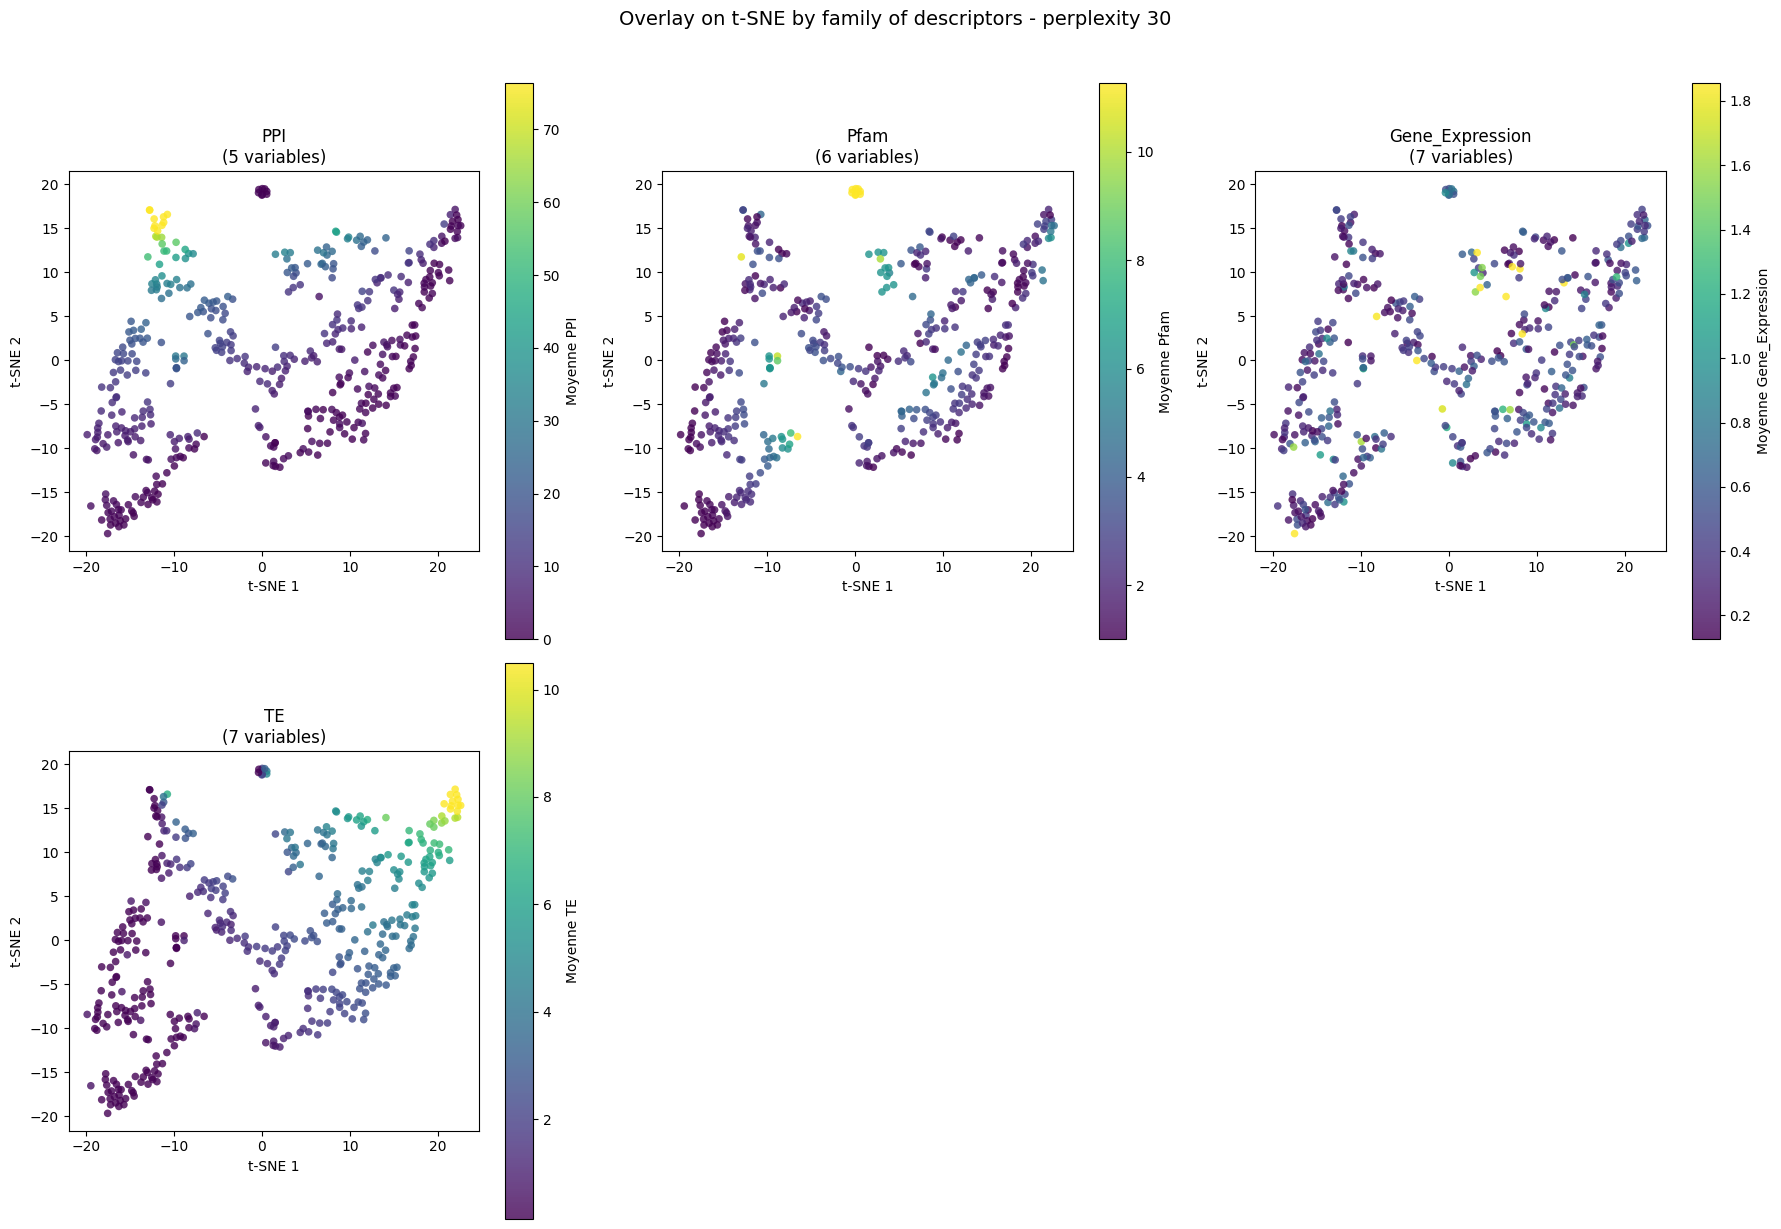

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
perplexity = 30

# tsne = TSNE(
#     n_components=2,
#     perplexity=perplexity,
#     learning_rate='auto',
#     max_iter=1000,
#     init='random',
#     random_state=42,
# )

# X_tsne_random = tsne.fit_transform(X_scaled)

# df_tsne_random = pd.DataFrame(X_tsne_random, columns=['tSNE_1', 'tSNE_2'])
# df_tsne_random['orig_index'] = df.index

for i, (group_name, cols) in enumerate(categories.items()):
    # Garder uniquement les colonnes présentes
    cols_present = [c for c in cols if c in X_num.columns]
    if not cols_present:
        axes[i].set_visible(False)
        continue

    vals = X_num[cols_present].mean(axis=1).values

    vmin, vmax = np.nanpercentile(vals, 2), np.nanpercentile(vals, 98)

    sc = axes[i].scatter(
        df_tsne_random['tSNE_1'], df_tsne_random['tSNE_2'],
        c=vals, cmap='viridis', vmin=vmin, vmax=vmax,
        alpha=0.8, s=30, edgecolors='none'
    )
    axes[i].set_title(f'{group_name}\n({len(cols_present)} variables)', fontsize=12)
    axes[i].set_xlabel('t-SNE 1')
    axes[i].set_ylabel('t-SNE 2')
    axes[i].set_aspect('equal')
    plt.colorbar(sc, ax=axes[i], label=f'Moyenne {group_name}')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle(f'Overlay on t-SNE by family of descriptors - perplexity {perplexity}', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('Plots/t_SNE_family/sans_pca/overlay_groupes.png', dpi=150, bbox_inches='tight')
plt.show()

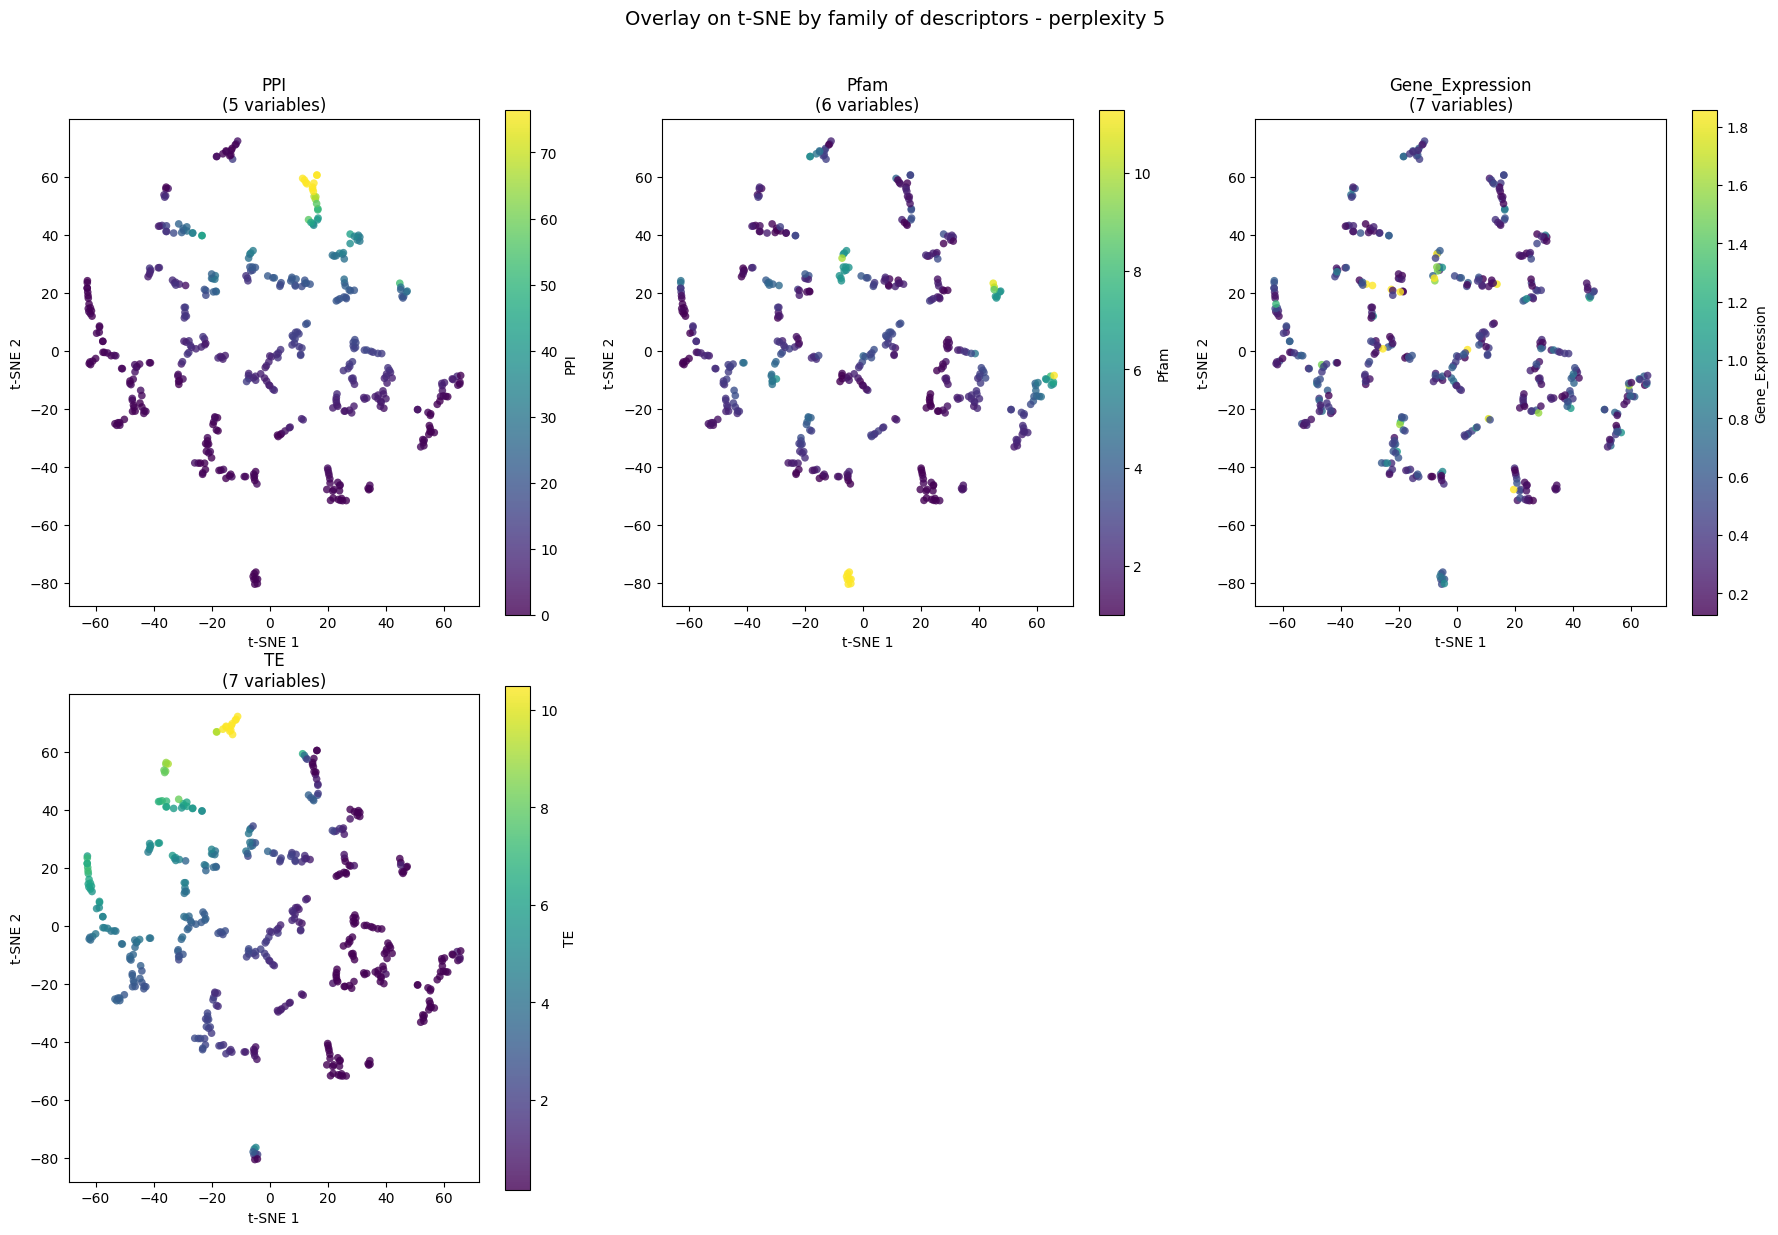

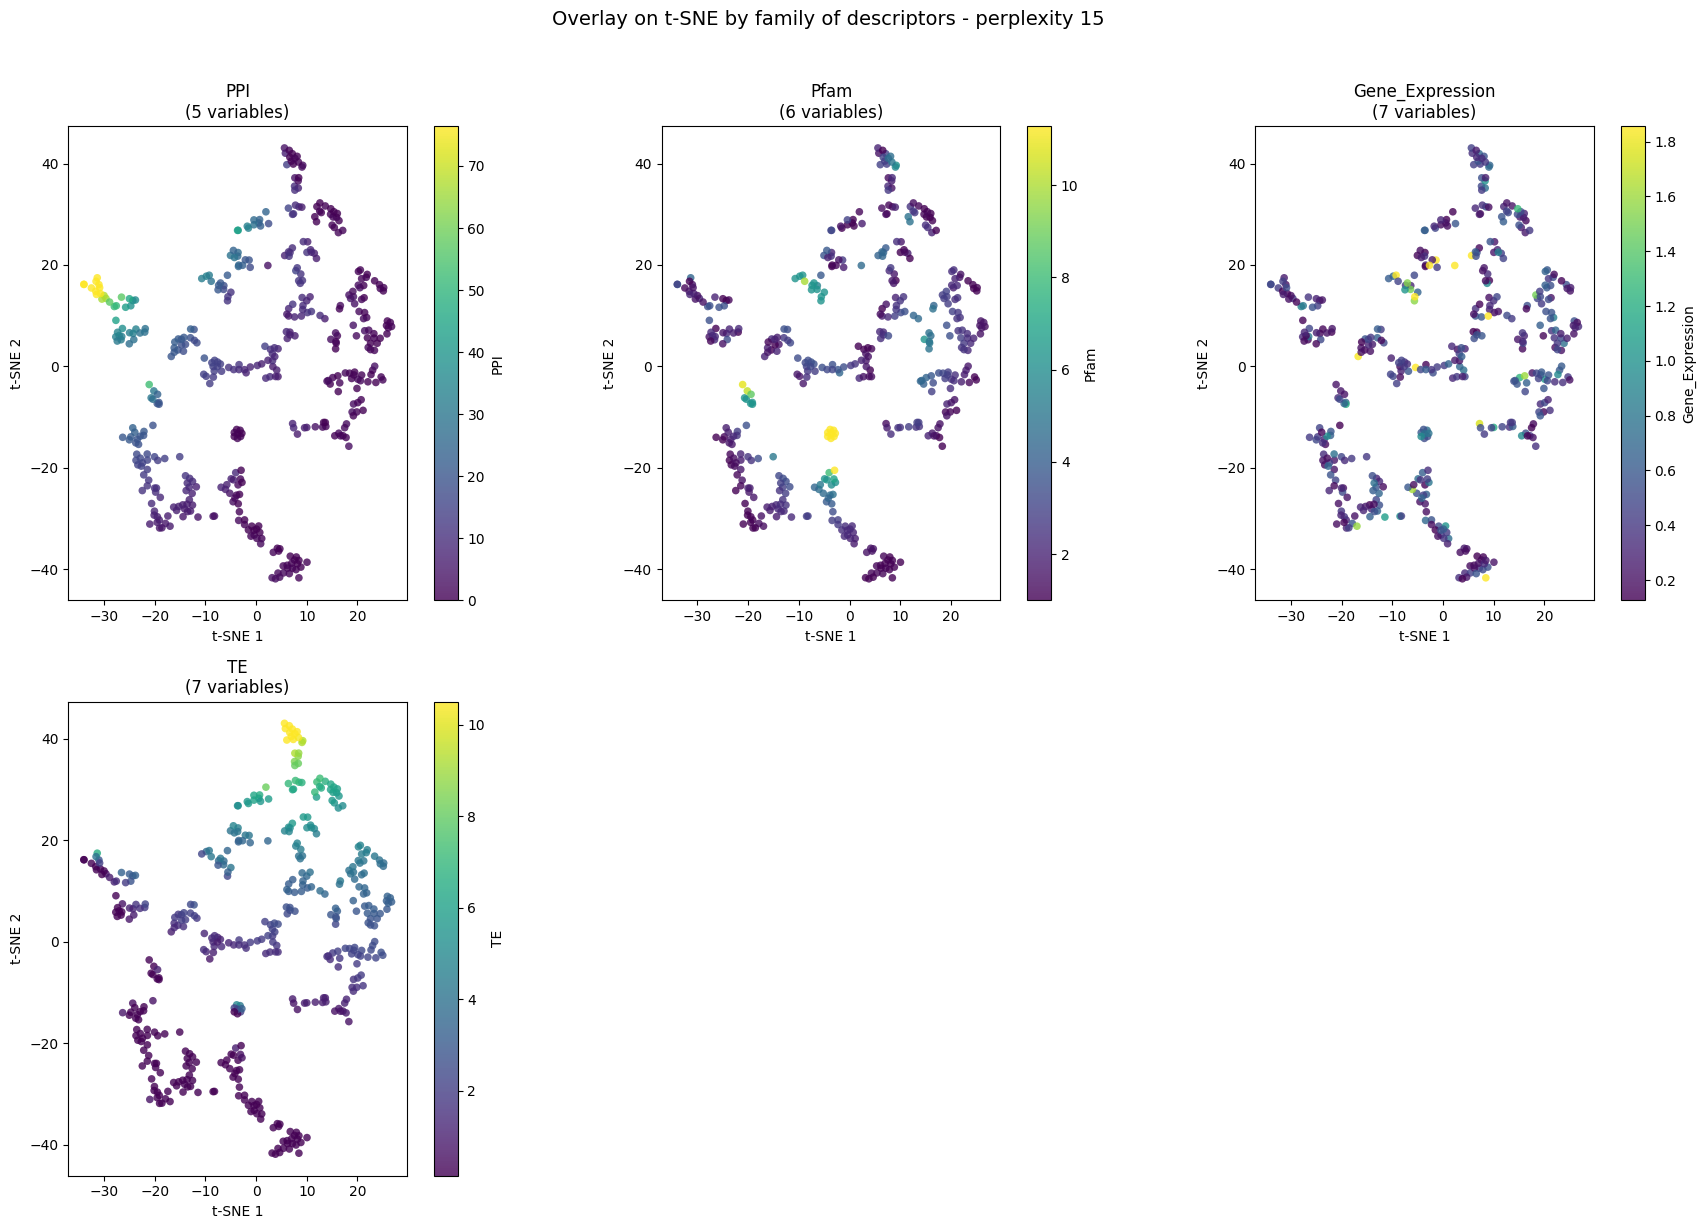

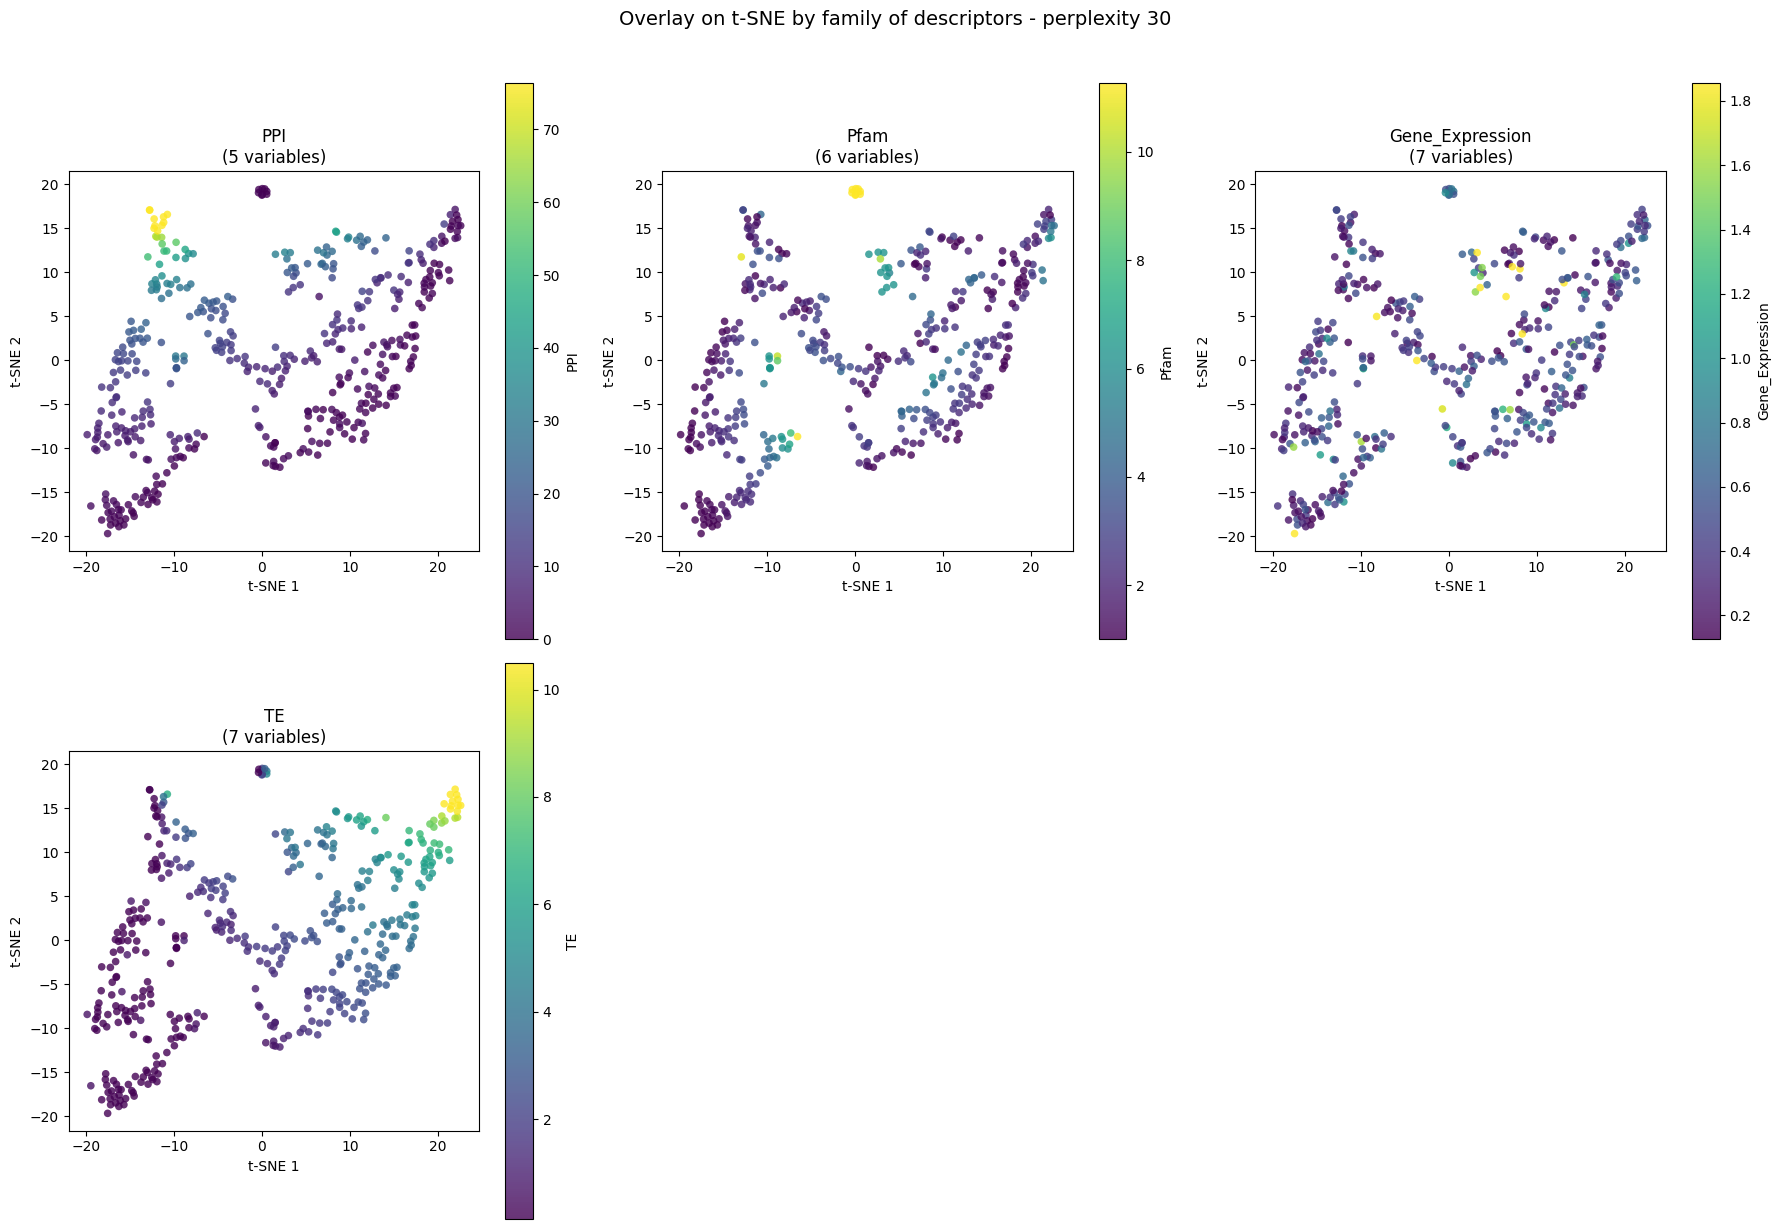

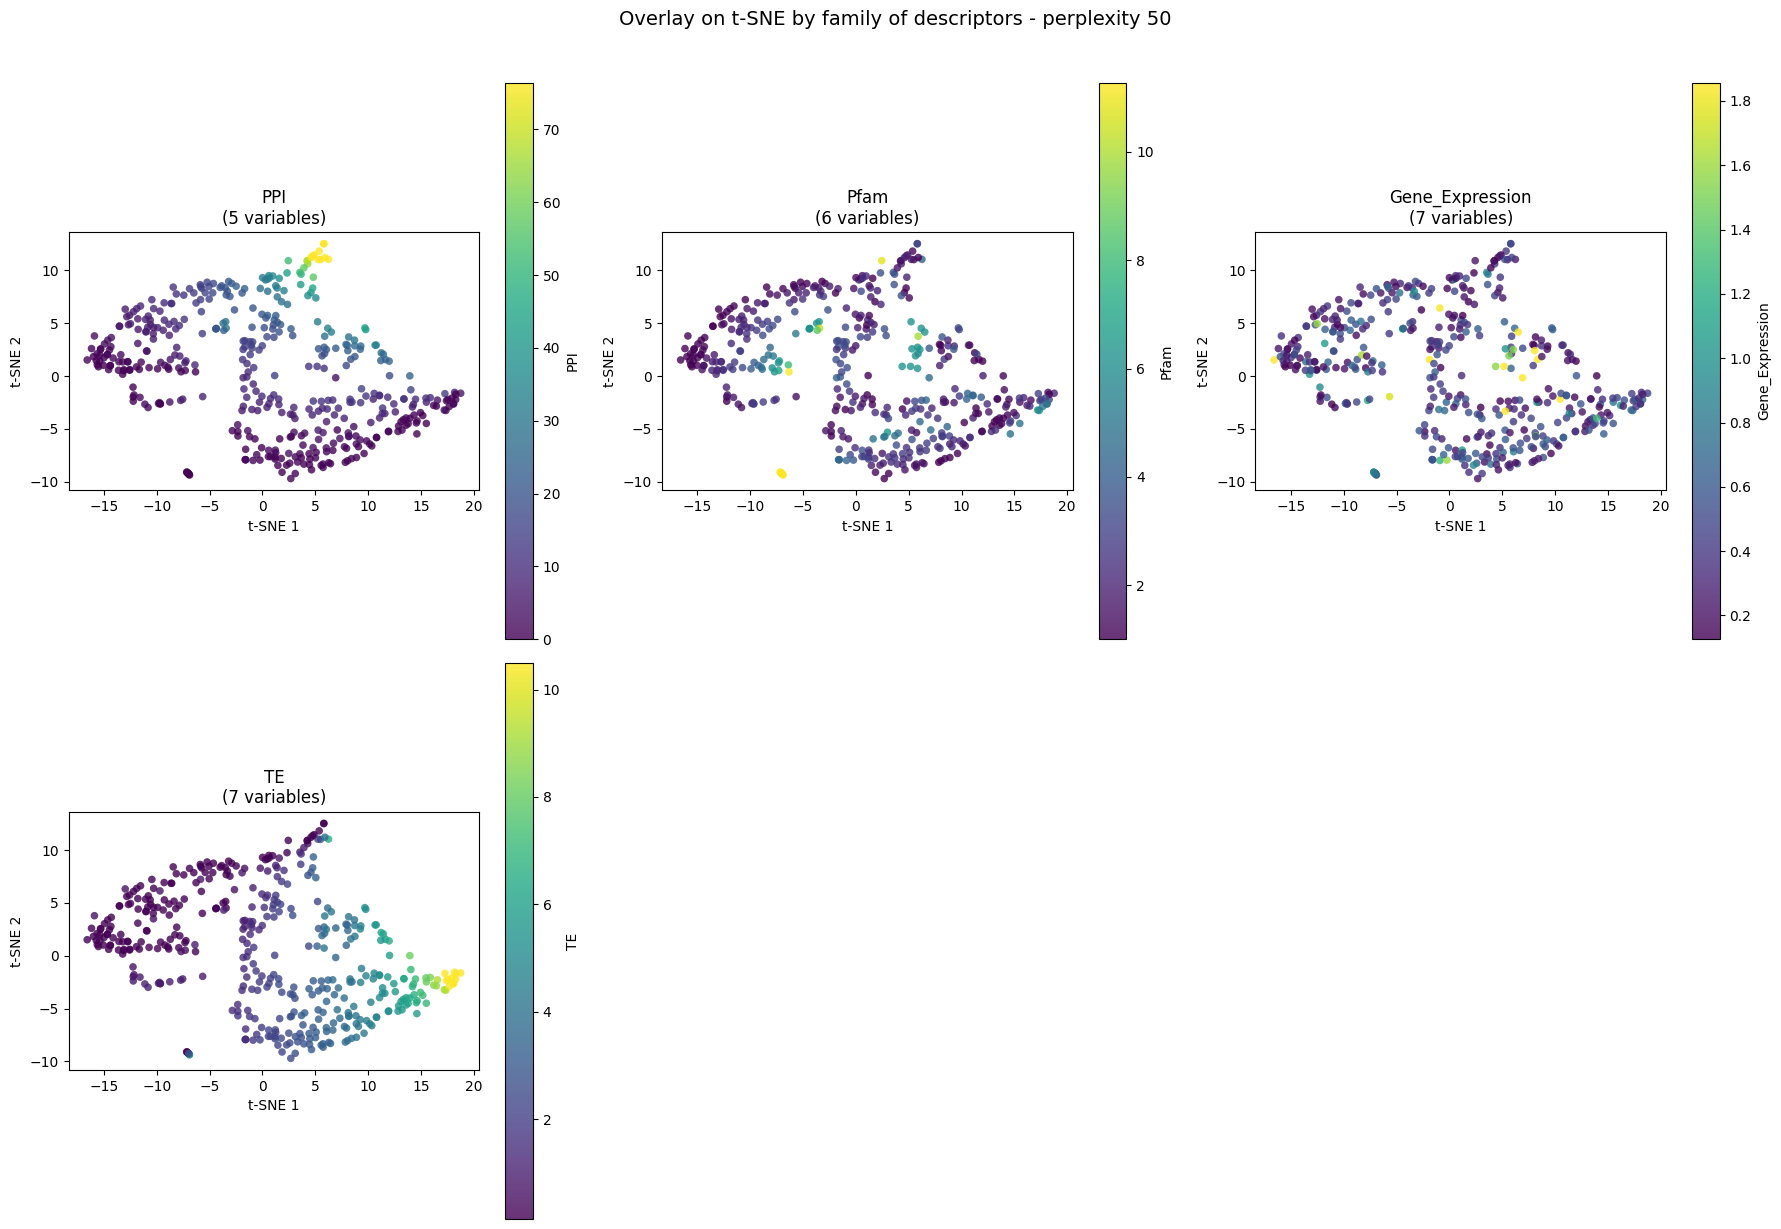

In [15]:
perplexities = [5, 15, 30, 50]

for perplexity in perplexities:
    # Recalcul du t-SNE pour cette perplexité
    tsne = TSNE(n_components=2, perplexity=perplexity, init='random', random_state=42, max_iter=1000)
    tsne_coords = tsne.fit_transform(X_scaled)
    df_tsne_perp = pd.DataFrame(tsne_coords, columns=['tSNE_1', 'tSNE_2'])

    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    axes = axes.flatten()

    last_i = 0
    for i, (group_name, cols) in enumerate(categories.items()):
        cols_present = [c for c in cols if c in X_num.columns]

        if len(cols_present) <= 2:
            axes[i].set_visible(False)
            continue

        vals = X_num[cols_present].mean(axis=1).values
        vmin, vmax = np.nanpercentile(vals, 2), np.nanpercentile(vals, 98)

        sc = axes[i].scatter(
            df_tsne_perp['tSNE_1'], df_tsne_perp['tSNE_2'],
            c=vals, cmap='viridis', vmin=vmin, vmax=vmax,
            alpha=0.8, s=30, edgecolors='none'
        )
        axes[i].set_title(f'{group_name}\n({len(cols_present)} variables)', fontsize=12)
        axes[i].set_xlabel('t-SNE 1')
        axes[i].set_ylabel('t-SNE 2')
        axes[i].set_aspect('equal')
        plt.colorbar(sc, ax=axes[i], label=f'{group_name}')
        last_i = i

    for j in range(last_i + 1, len(axes)):
        axes[j].set_visible(False)

    plt.suptitle(f'Overlay on t-SNE by family of descriptors - perplexity {perplexity}', fontsize=14, y=1.02)
    plt.tight_layout()
    plt.savefig(f'Plots/t_SNE_family/sans_pca/groupes_perp{perplexity}.png', dpi=150, bbox_inches='tight')
    plt.show()

## t-SNE avec PCA ##

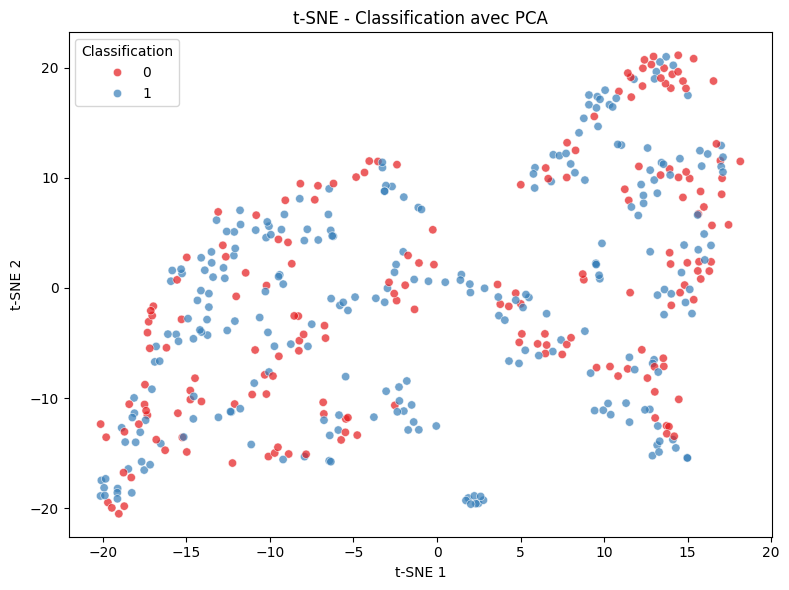

In [16]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate='auto',
    max_iter=1000,
    init='pca',
    random_state=42,
)

# Récupérer Classification pour t-SNE 
y_train = pd.read_csv("Données/Y_train_clean.csv")

X_tsne_random_pca = tsne.fit_transform(X_scaled)

df_tsne_random_pca = pd.DataFrame(X_tsne_random_pca, columns=['tSNE_1', 'tSNE_2'])
df_tsne_random_pca['orig_index'] = df.index

# Visualisation t-SNE colorée par la Classification
plt.figure(figsize=(8, 6))
sns.scatterplot(x=df_tsne_random_pca['tSNE_1'], y=df_tsne_random_pca['tSNE_2'], hue=y_train['Classification'], palette='Set1', alpha=0.7)
plt.title('t-SNE - Classification avec PCA')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.legend(title='Classification')
plt.tight_layout()
plt.savefig('Plots/t_SNE_family/avec_pca/tsne_classification.png', dpi=300)
plt.show()

### Analyse perplexité t-SNE Classification avec PCA ###

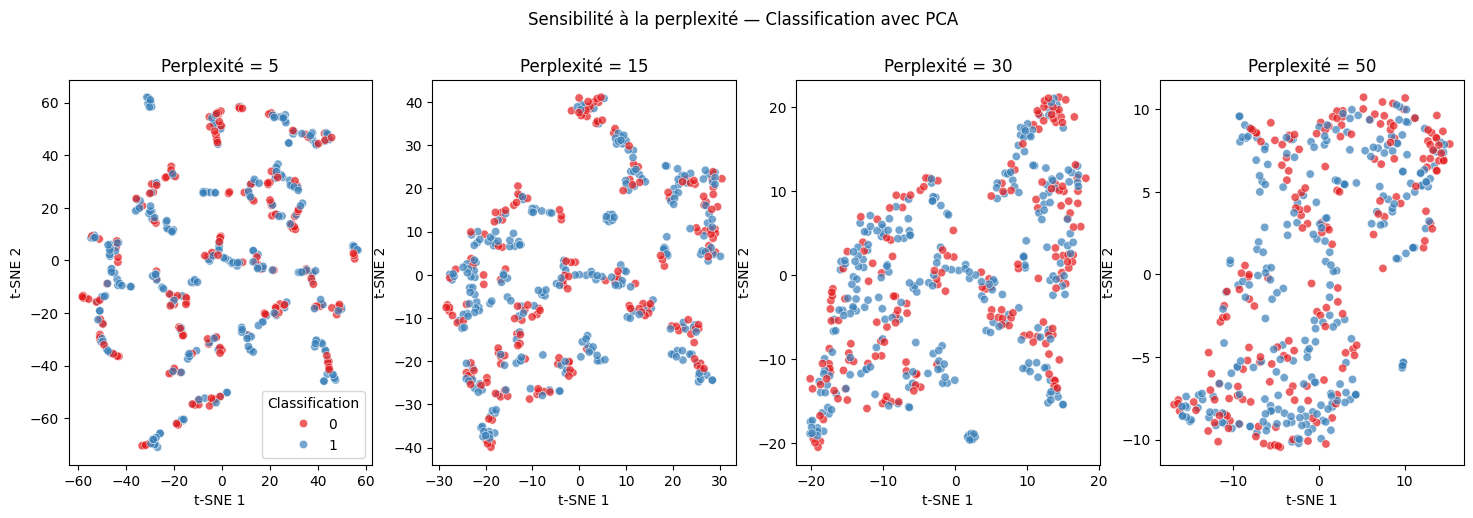

In [17]:
# Analyse de la sensibilité de t-SNE à la perplexité
perplexities = [5, 15, 30, 50]
fig, axes = plt.subplots(1, len(perplexities), figsize=(18, 5))
group_col = 'Classification' if 'Classification' in y_train.columns else print("Colonne 'Classification' non trouvée.")
for i, perp in enumerate(perplexities):
    tsne = TSNE(
        n_components=2,
        perplexity=perp,
        learning_rate='auto',
        max_iter=1000,
        init='pca',
        random_state=42,
    )
    X_tsne_perp_pca = tsne.fit_transform(X_scaled)
    df_tsne_perp_pca = pd.DataFrame(X_tsne_perp_pca, columns=['tSNE_1', 'tSNE_2'])
    df_tsne_perp_pca['orig_index'] = df.index

    sns.scatterplot(x=df_tsne_perp_pca['tSNE_1'], y=df_tsne_perp_pca['tSNE_2'], hue=y_train['Classification'], palette='Set1', alpha=0.7, ax=axes[i])
    axes[i].set_title(f'Perplexité = {perp}')
    axes[i].set_xlabel('t-SNE 1')
    axes[i].set_ylabel('t-SNE 2')
    if i == 0:
        axes[i].legend(title='Classification')
    else:
        axes[i].get_legend().remove()
plt.suptitle(f"Sensibilité à la perplexité — {group_col} avec PCA", y=1.02)
# Supprimer les axes vides s'il y en a
for j in range(i+1, len(axes)):
    axes[j].set_visible(False)


### Overlay des features numériques avec PCA ###

On superpose une variable continue sur la carte t-SNE pour voir comment elle se structure dans l'espace réduit.

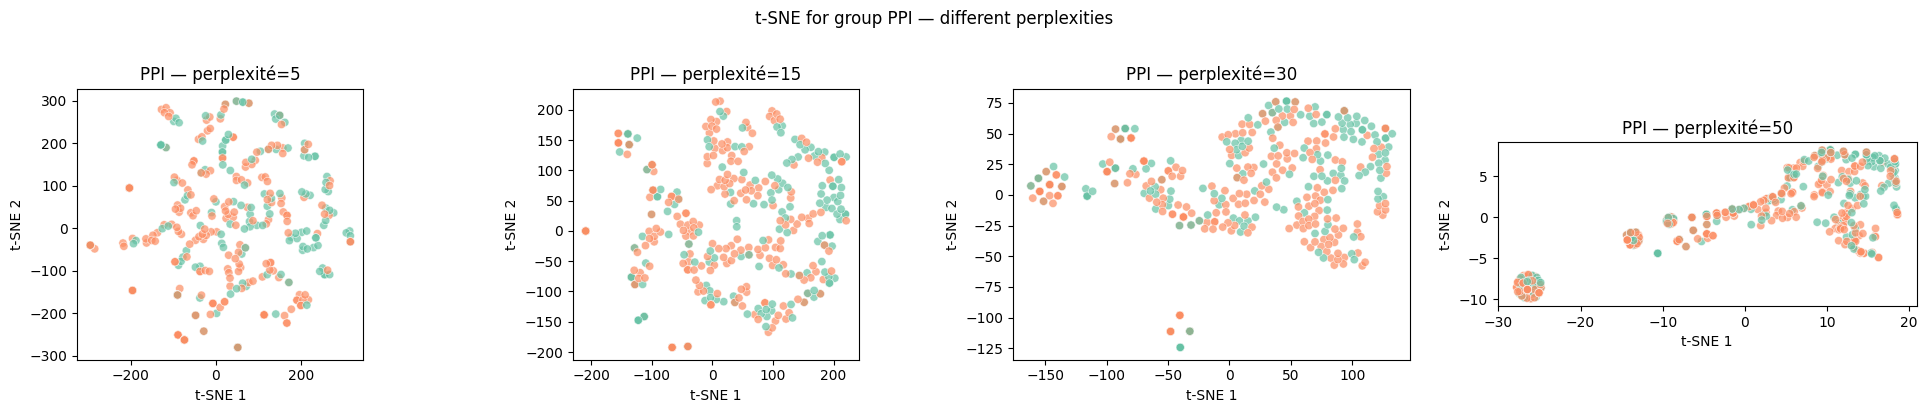

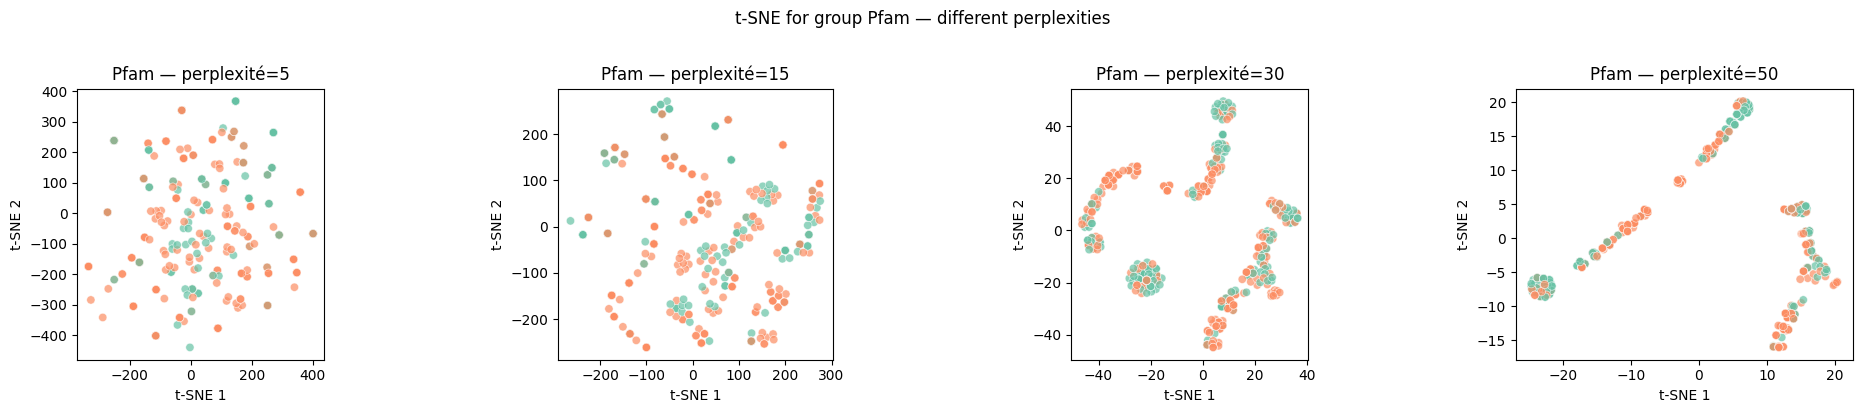

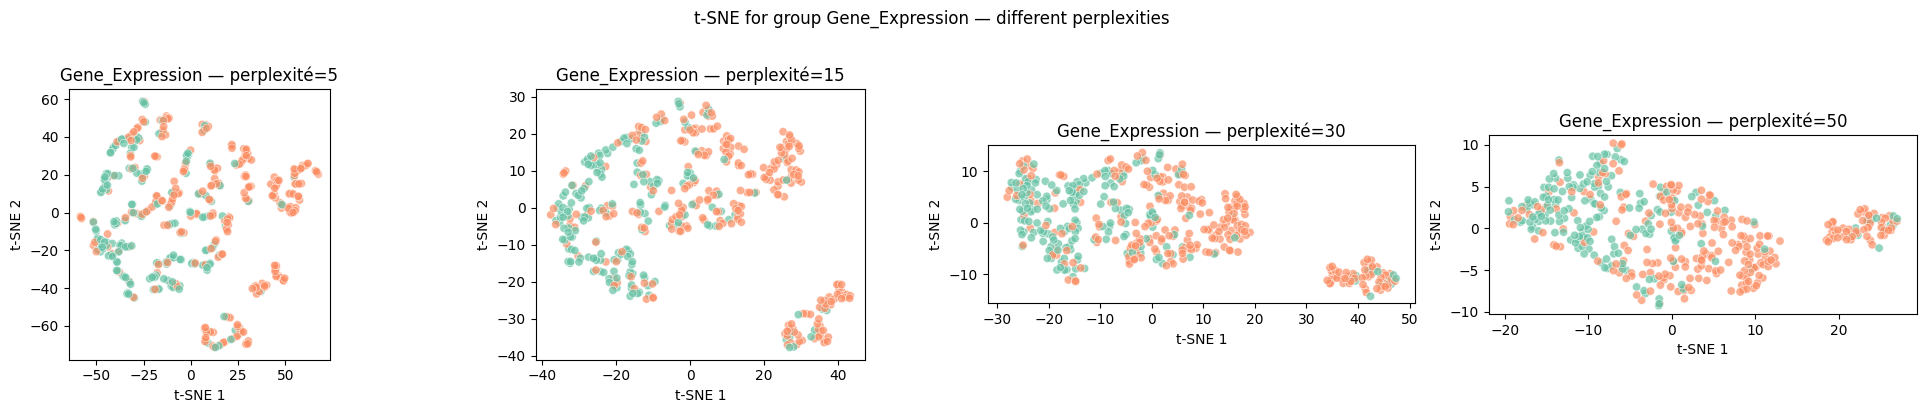

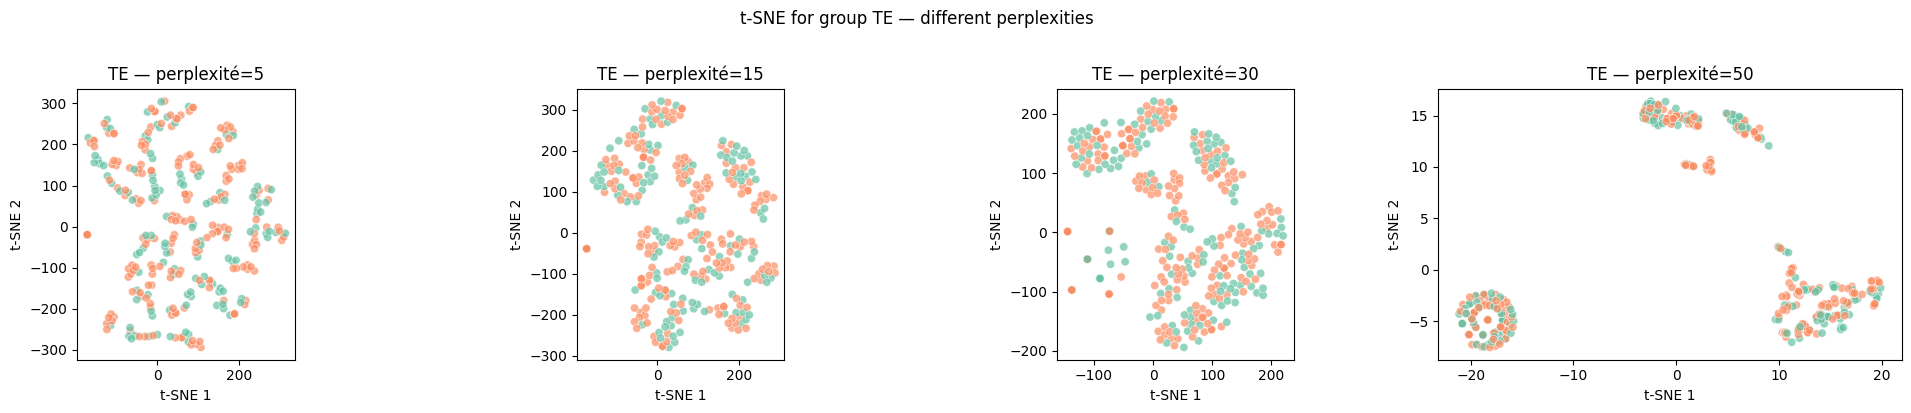

In [18]:
# Pour chaque groupe, créer une figure avec les 4 perplexités en sous-plot
import os
perplexities = [5, 15, 30, 50]

# Récupérer les labels de Classification et s'assurer de l'alignement des index
y_train = pd.read_csv("Données/Y_train_clean.csv")
y_train = y_train.reindex(df.index).reset_index(drop=True)

# Si la colonne n'existe pas, on arrête proprement
group_col = 'Classification'
if group_col not in y_train.columns:
    raise KeyError(f"Colonne '{group_col}' absente dans Données/Y_train_clean.csv")

group_labels = sorted(y_train[group_col].dropna().unique())
palette = sns.color_palette('Set2', n_colors=len(group_labels))

# Boucle sur les groupes
for group, cols in categories.items():
    if len(cols) <= 2:
        print(f"Le groupe '{group}' a moins de 2 descripteurs, t-SNE non applicable. Skipping.")
        continue

    X_group = X_num[cols].values
    X_group_scaled = StandardScaler().fit_transform(X_group)

    fig, axes = plt.subplots(1, len(perplexities), figsize=(5*len(perplexities), 4))
    # s'assurer que axes est itérable (au cas où len(perplexities)==1)
    axes = np.atleast_1d(axes)

    for ax, perp in zip(axes, perplexities):
        tsne = TSNE(n_components=2, 
                    perplexity=perp, 
                    learning_rate='auto', 
                    max_iter=1000, init='pca', 
                    random_state=42)
        emb = tsne.fit_transform(X_group_scaled)

        df_tsne_group_pca = pd.DataFrame(emb, columns=['tSNE_1', 'tSNE_2'])
        df_tsne_group_pca['Classification'] = y_train[group_col]

        sns.scatterplot(x='tSNE_1', y='tSNE_2', hue='Classification', data=df_tsne_group_pca, palette=palette, alpha=0.7, ax=ax, legend=False)
        ax.set_title(f'{group} — perplexité={perp}')
        ax.set_xlabel('t-SNE 1')
        ax.set_ylabel('t-SNE 2')
        ax.set_aspect('equal')

    # ajouter une légende commune à la figure (si des labels existent)
    handles, labels = axes[0].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, title='Classification', loc='upper right')

    plt.suptitle(f't-SNE for group {group} — different perplexities', y=1.02)
    plt.tight_layout()
    out_path = f'Plots/t_SNE_family/avec_pca/{group}perplexities.png'
    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    plt.savefig(out_path, dpi=150, bbox_inches='tight')
    plt.show()

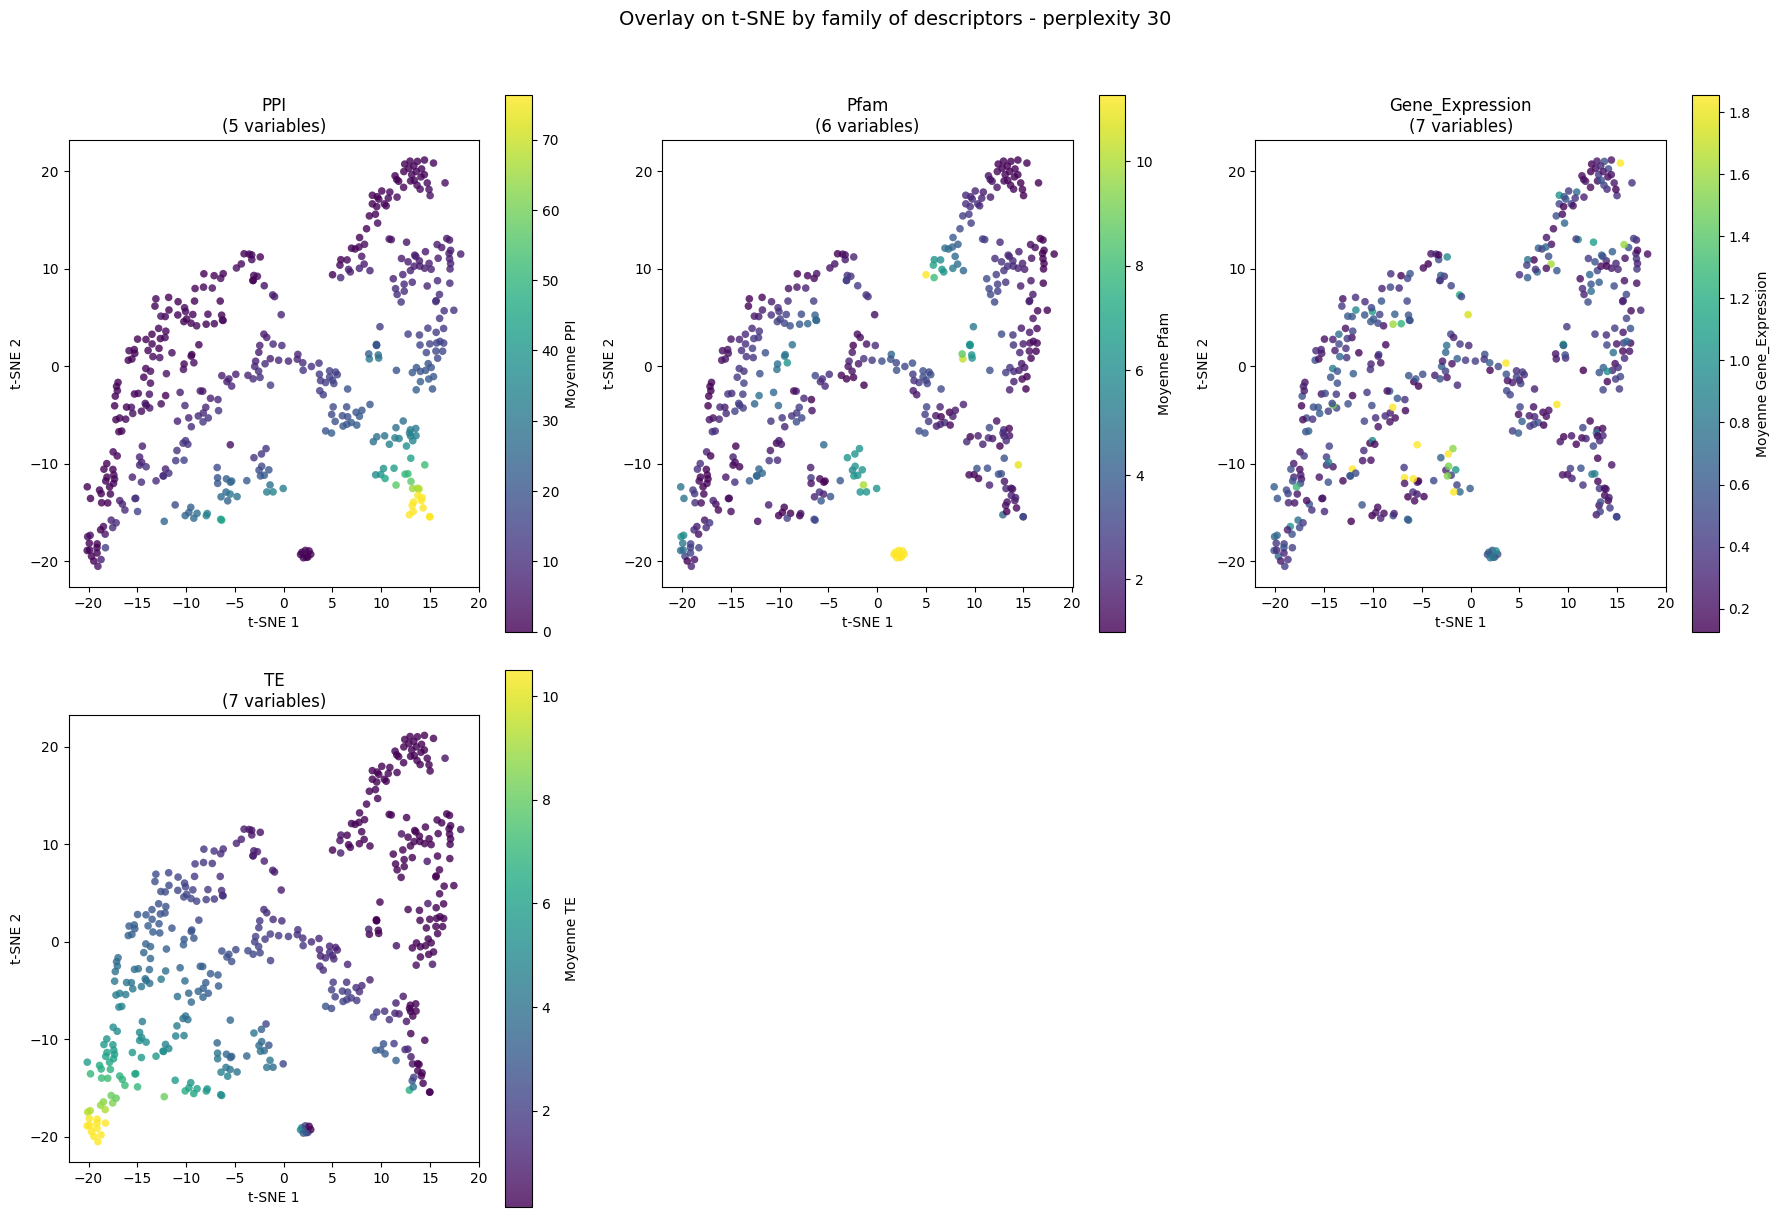

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
perplexity = 30

for i, (group_name, cols) in enumerate(categories.items()):
    # Garder uniquement les colonnes présentes
    cols_present = [c for c in cols if c in X_num.columns]
    if not cols_present:
        axes[i].set_visible(False)
        continue

    vals = X_num[cols_present].mean(axis=1).values

    vmin, vmax = np.nanpercentile(vals, 2), np.nanpercentile(vals, 98)

    sc = axes[i].scatter(
        df_tsne_random_pca['tSNE_1'], df_tsne_random_pca['tSNE_2'],
        c=vals, cmap='viridis', vmin=vmin, vmax=vmax,
        alpha=0.8, s=30, edgecolors='none'
    )
    axes[i].set_title(f'{group_name}\n({len(cols_present)} variables)', fontsize=12)
    axes[i].set_xlabel('t-SNE 1')
    axes[i].set_ylabel('t-SNE 2')
    axes[i].set_aspect('equal')
    plt.colorbar(sc, ax=axes[i], label=f'Moyenne {group_name}')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle(f'Overlay on t-SNE by family of descriptors - perplexity {perplexity}', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('Plots/t_SNE_family/avec_pca/overlay_groupes.png', dpi=150, bbox_inches='tight')
plt.show()

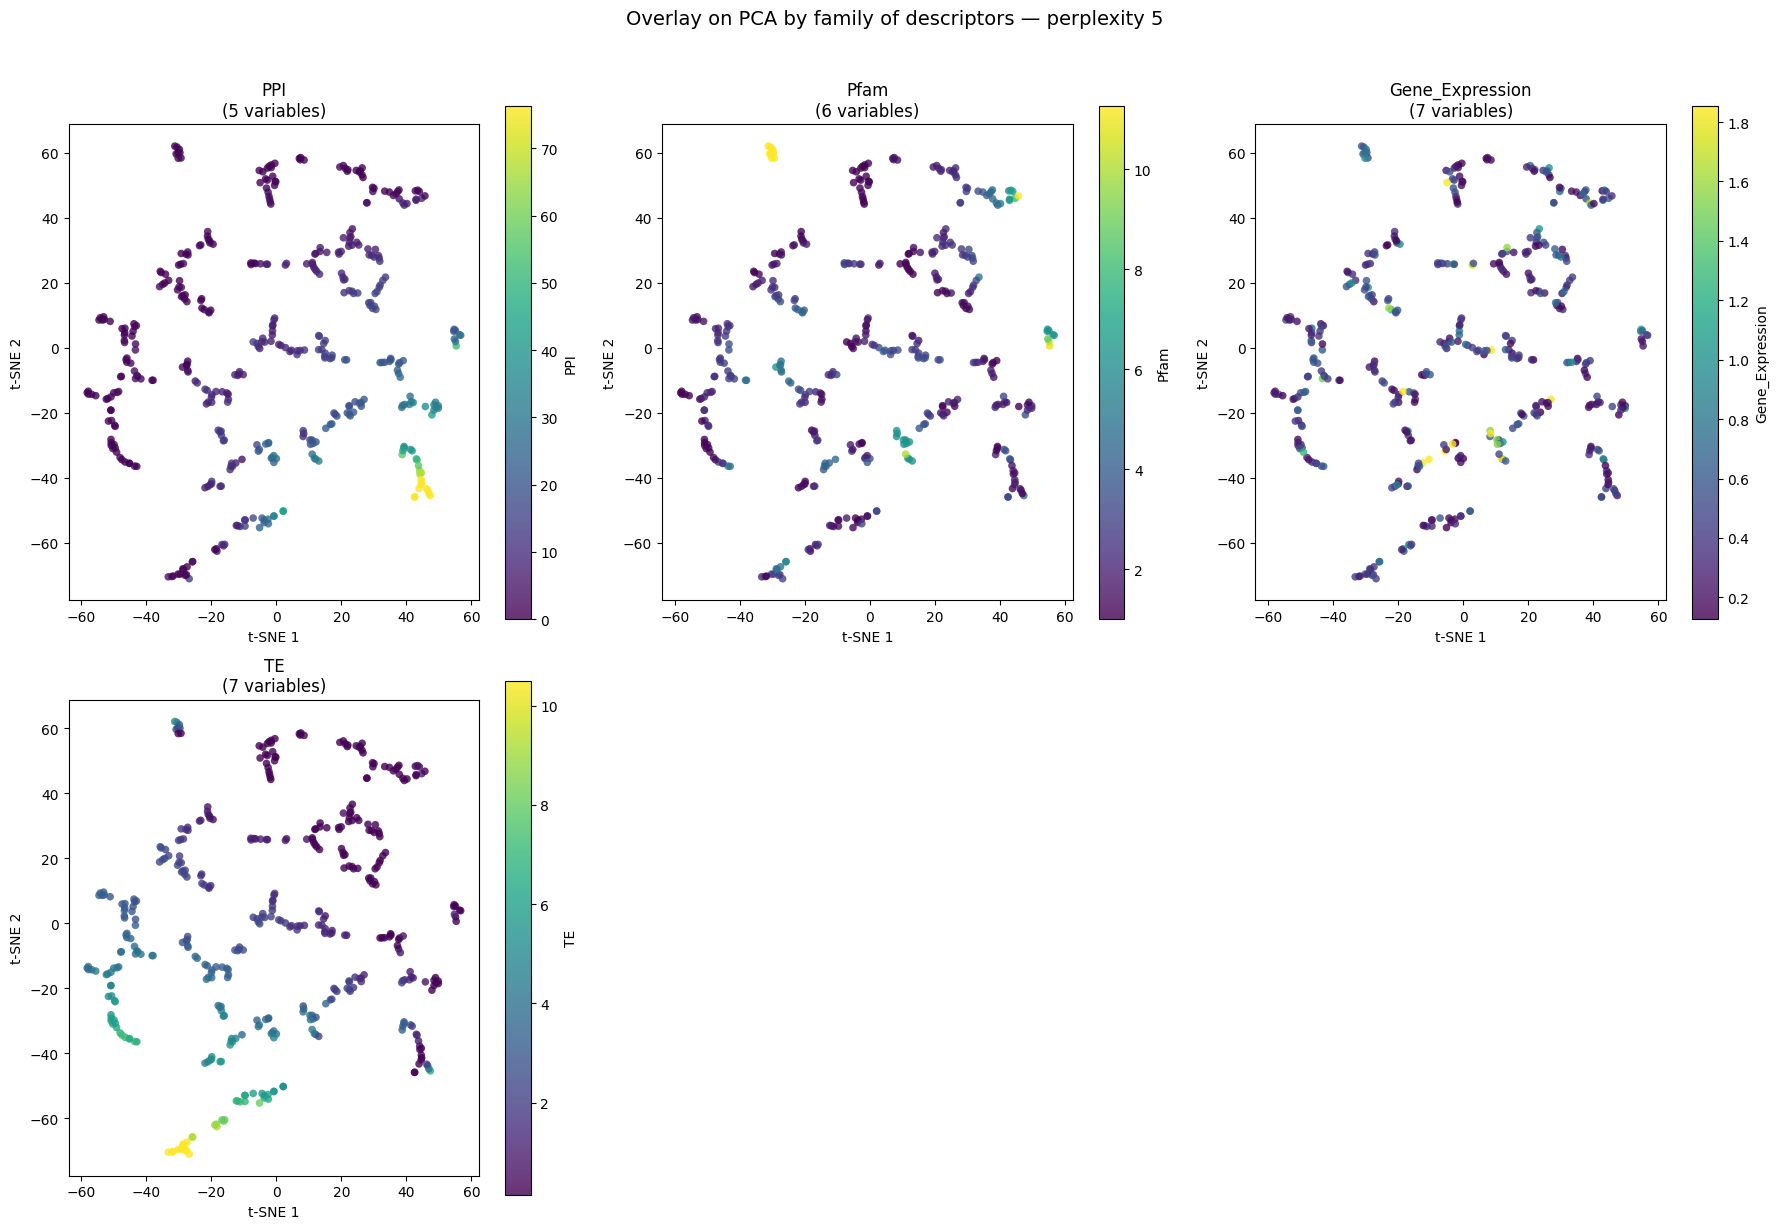

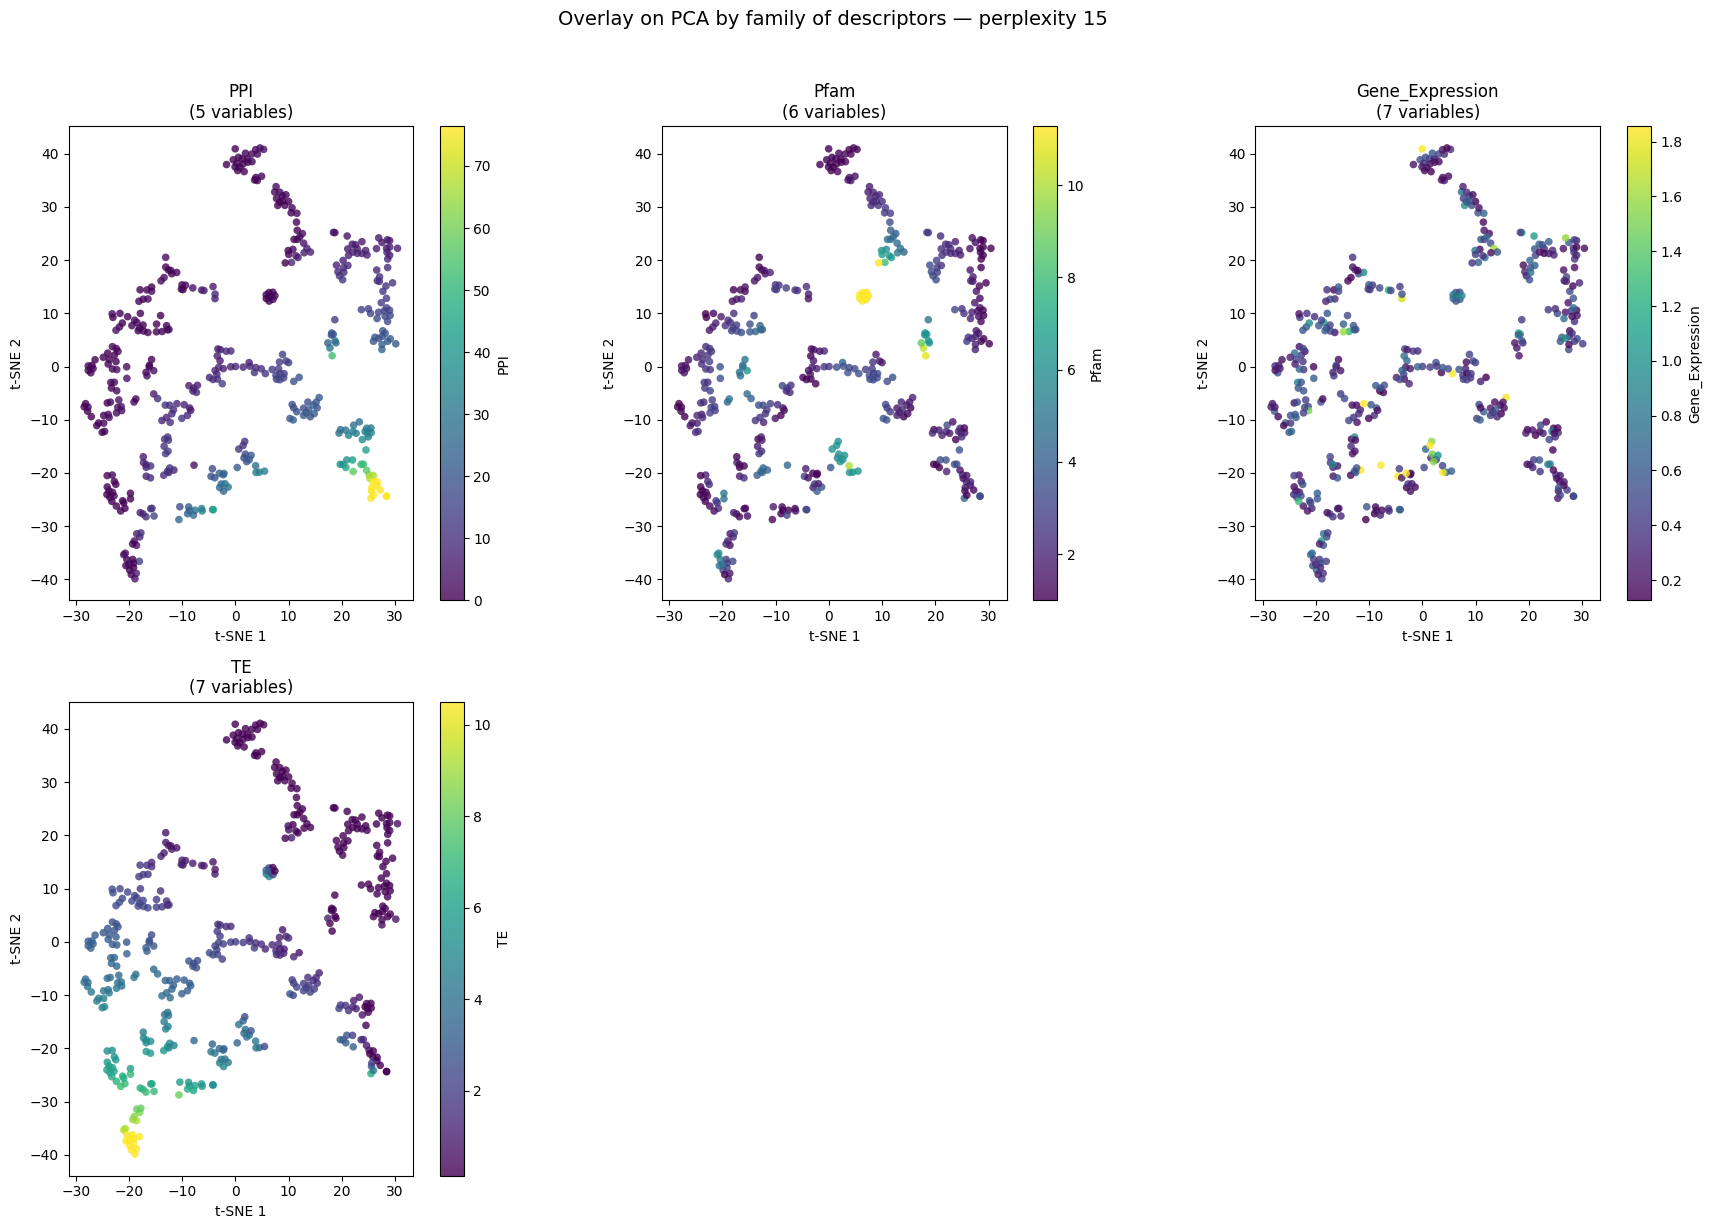

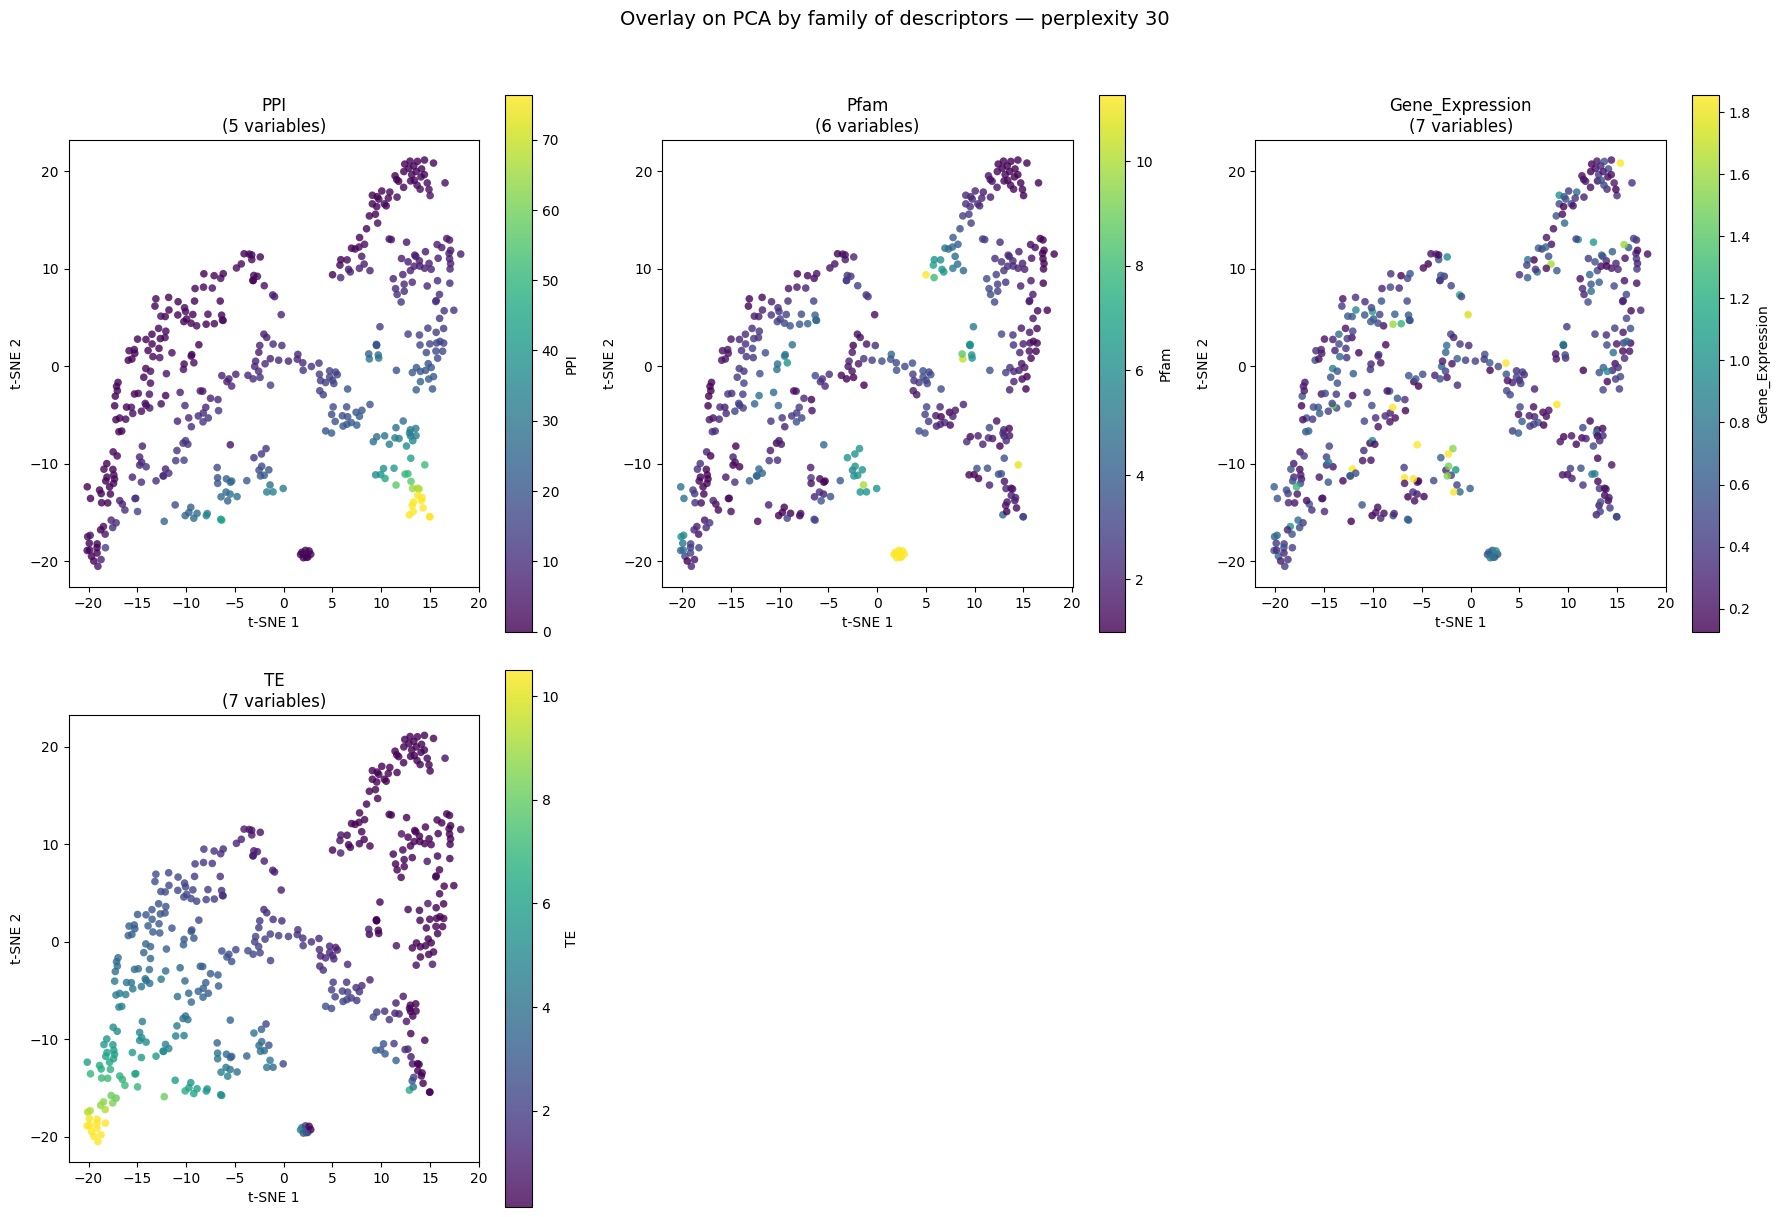

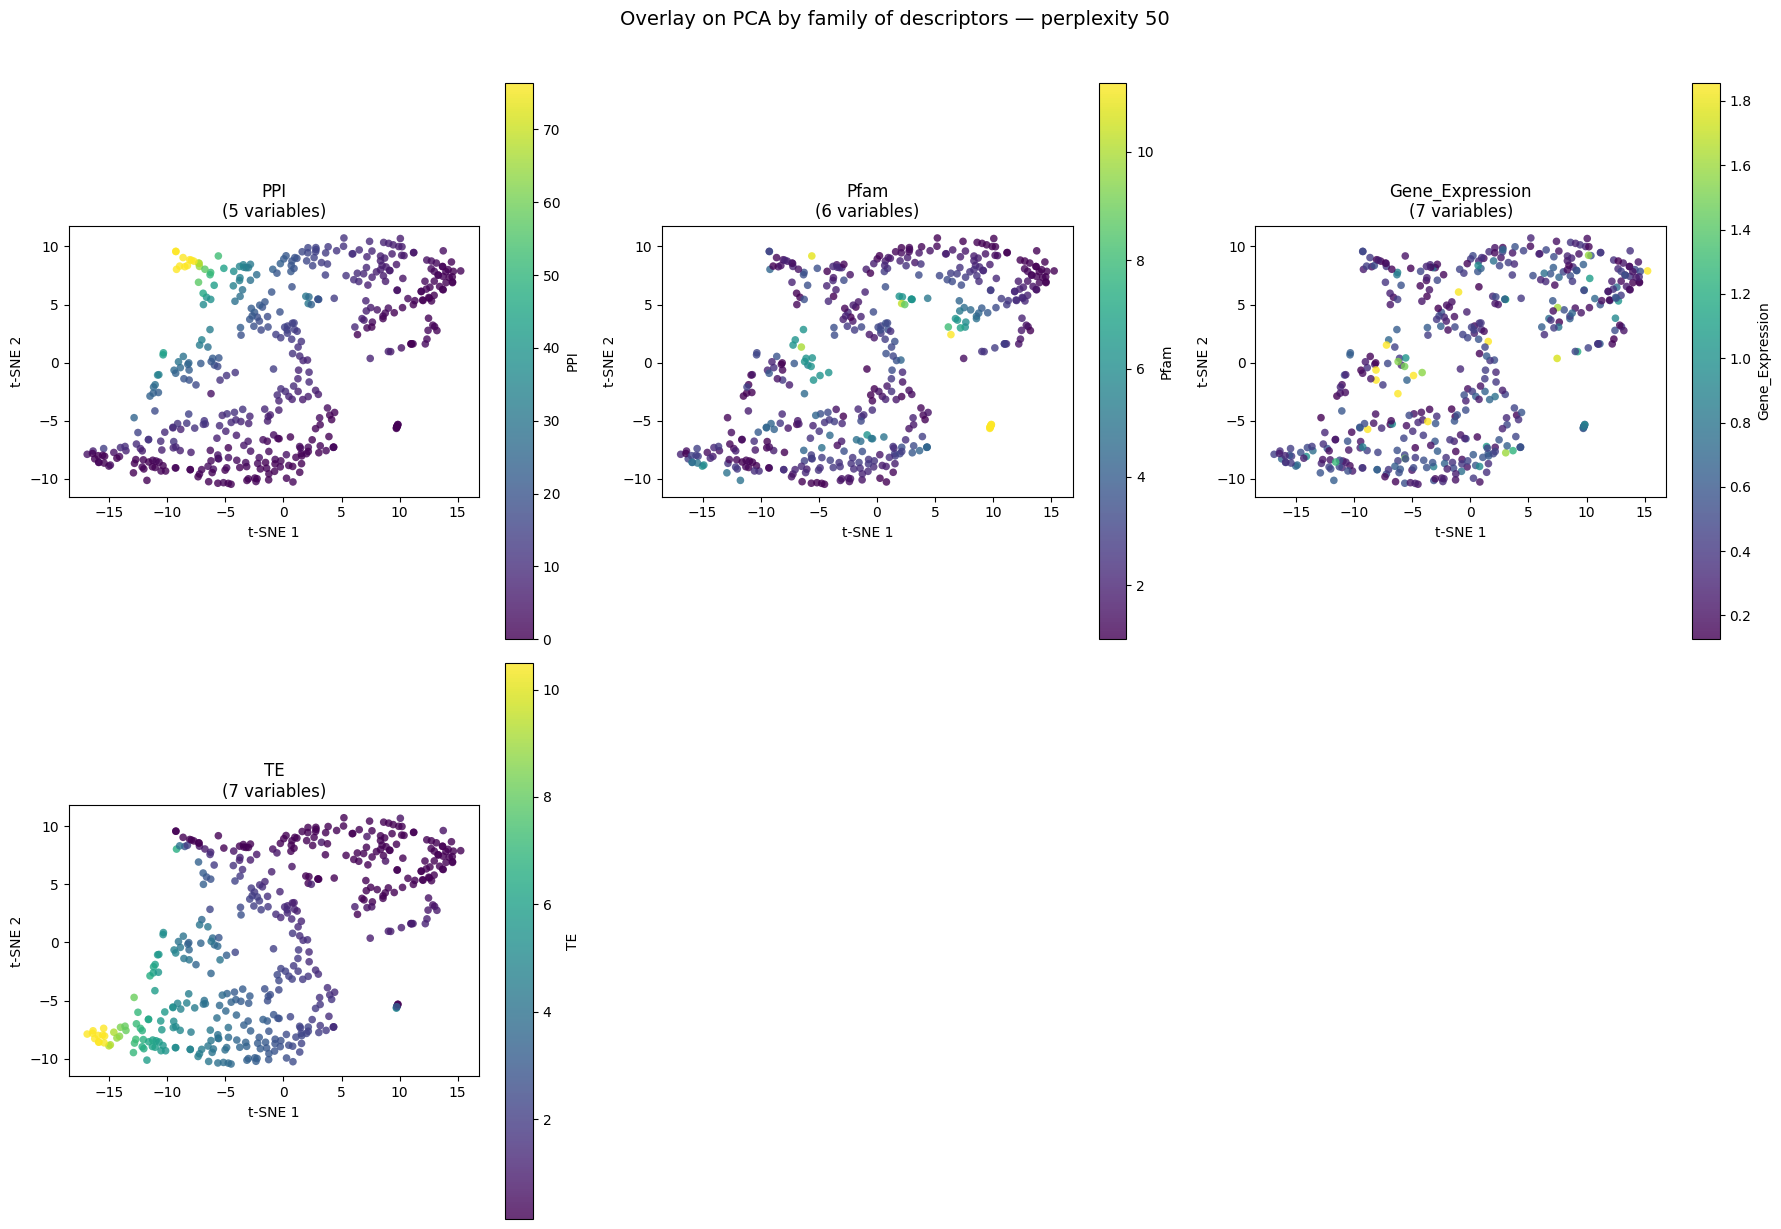

In [20]:
perplexities = [5, 15, 30, 50]

for perplexity in perplexities:
    # Recalcul du t-SNE pour cette perplexité
    tsne = TSNE(n_components=2, perplexity=perplexity, init='pca', random_state=42, max_iter=1000)
    tsne_coords = tsne.fit_transform(X_scaled)
    df_tsne_group_pca = pd.DataFrame(tsne_coords, columns=['tSNE_1', 'tSNE_2'])

    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    axes = axes.flatten()

    last_i = 0
    for i, (group_name, cols) in enumerate(categories.items()):
        cols_present = [c for c in cols if c in X_num.columns]

        if len(cols_present) <= 2:
            axes[i].set_visible(False)
            continue

        vals = X_num[cols_present].mean(axis=1).values
        vmin, vmax = np.nanpercentile(vals, 2), np.nanpercentile(vals, 98)

        sc = axes[i].scatter(
            df_tsne_group_pca['tSNE_1'], df_tsne_group_pca['tSNE_2'],
            c=vals, cmap='viridis', vmin=vmin, vmax=vmax,
            alpha=0.8, s=30, edgecolors='none'
        )
        axes[i].set_title(f'{group_name}\n({len(cols_present)} variables)', fontsize=12)
        axes[i].set_xlabel('t-SNE 1')
        axes[i].set_ylabel('t-SNE 2')
        axes[i].set_aspect('equal')
        plt.colorbar(sc, ax=axes[i], label=f'{group_name}')
        last_i = i

    for j in range(last_i + 1, len(axes)):
        axes[j].set_visible(False)

    plt.suptitle(f'Overlay on PCA by family of descriptors — perplexity {perplexity}', fontsize=14, y=1.02)
    plt.tight_layout()
    plt.savefig(f'Plots/t_SNE_family/avec_pca/overlay_groupes_perp{perplexity}.png', dpi=150, bbox_inches='tight')
    plt.show()